## Análise de Trade-off de Modelos BERT

A tabela abaixo apresenta os modelos BERT disponíveis e suas características principais, que podem ser utilizadas para uma análise de trade-off ao selecionar o modelo mais adequado para uma tarefa específica. A escolha ideal depende de fatores como o idioma do corpus, a necessidade de especialização jurídica e os recursos computacionais disponíveis (número de camadas influencia o tamanho e a complexidade do modelo).

| ID | Endpoint                     | Descrição                      | Tipo de Fine-Tuning | Nº Camadas |
|----|------------------------------|--------------------------------|---------------------|------------|
| 1  | `raquelsilveira/legalbertpt_fp` | LegalBERTpt Jurídico           | Legal PT-BR         | 12         |
| 2  | `rufimelo/Legal-BERTimbau-base` | Legal-BERTimbau Jurídico Base  | Legal PT-BR         | 12         |
| 3  | `rufimelo/Legal-BERTimbau-large`| Legal-BERTimbau Jurídico Large | Legal PT-BR         | 24         |
| 4  | `neuralmind/bert-base-portuguese-cased` | BERTimbau Base                 | PT-BR               | 12         |
| 5  | `neuralmind/bert-large-portuguese-cased`| BERTimbau Large                | PT-BR               | 24         |
| 6  | `google-bert/bert-base-multilingual-cased`| BERT Multilingual Base         | Multilingual        | 12         |
| 7  | `FacebookAI/xlm-roberta-base` | ROBERTA Multilingual Base      | Multilingual        | 12         |

### Models - Como usar esta tabela para a análise de Trade-off:

1.  **Idioma e Especialização:** Se a tarefa envolve textos jurídicos em português, modelos como `LegalBERTpt Jurídico` ou `Legal-BERTimbau Jurídico` são preferíveis devido ao seu pré-treinamento em dados específicos do domínio.
2.  **Performance vs. Recurso:** Modelos 'Large' (e.g., `Legal-BERTimbau Jurídico Large`, `BERTimbau Large`) possuem mais camadas e, portanto, maior capacidade de aprendizado, mas exigem mais recursos computacionais (GPU/memória) e tempo de treinamento. Modelos 'Base' ou com menos camadas são mais leves e rápidos.
3.  **Multilingue:** Para tarefas que envolvem múltiplos idiomas, os modelos Multilingual (BERT Multilingual Base, ROBERTA Multilingual Base) são a escolha adequada.
4.  **Baseline:** O `BERTimbau Base` pode servir como um bom ponto de partida ou baseline para tarefas em português sem a necessidade inicial de especialização jurídica.

A tabela abaixo detalha as diferentes abordagens de processamento de texto para lidar com o desafio de documentos extensos no contexto do fine-tuning de modelos BERT. A escolha da abordagem ideal depende do balanço entre a preservação da informação contextual, a redução da redundância e a eficiência computacional.

| ID | Abordagem                | Stride | Max Chunks | Pooling | Mínimo Tokens Chunk | Descrição                                                                      |
|----|--------------------------|--------|------------|---------|---------------------|--------------------------------------------------------------------------------|
| 1  | Truncation (512)         | 512    | 1          | max     | 1                   | Trunca o texto nos primeiros 512 tokens. Simples, mas perde contexto do meio/fim.|
| 2  | Mean Pooling - Stride 0  | 512    | (None)     | mean    | 8                   | Chunks sem sobreposição (512 tokens), com média dos embeddings dos chunks.     |
| 3  | Mean Pooling - Stride 64 | 64     | (None)     | mean    | 8                   | Chunks com sobreposição (stride 64), com média dos embeddings dos chunks.     |
| 4  | Mean Pooling - Stride 128| 128    | (None)     | mean    | 8                   | Chunks com sobreposição (stride 128), com média dos embeddings dos chunks.    |
| 5  | Mean Pooling - Stride 256| 256    | (None)     | mean    | 8                   | Chunks com sobreposição (stride 256), com média dos embeddings dos chunks.    |
| 6  | Max Pooling - Stride 0   | 512    | (None)     | max     | 8                   | Chunks sem sobreposição (512 tokens), com máximo dos embeddings dos chunks.    |
| 7  | Max Pooling - Stride 64  | 64     | (None)     | max     | 8                   | Chunks com sobreposição (stride 64), com máximo dos embeddings dos chunks.    |
| 8  | Max Pooling - Stride 128 | 128    | (None)     | max     | 8                   | Chunks com sobreposição (stride 128), com máximo dos embeddings dos chunks.   |
| 9  | Max Pooling - Stride 256 | 256    | (None)     | max     | 8                   | Chunks com sobreposição (stride 256), com máximo dos embeddings dos chunks.   |
| 10 | Head Tail - 128-382      | (None) | 1          | (None)  | (None)              | Combina os 128 tokens iniciais e 382 tokens finais do documento.                |
| 11 | Head Tail - 256-254      | (None) | 1          | (None)  | (None)              | Combina os 256 tokens iniciais e 254 tokens finais do documento.                |

### Technics - Como usar esta tabela para a análise de Trade-off:

1.  **Preservação Contextual:**
    *   **Truncation:** Simples, mas arrisca perder informações críticas no meio/final do texto.
    *   **Sliding Window (Mean/Max Pooling com Stride):** Mantém mais contexto, especialmente com `stride` menor (maior sobreposição). O `stride` 0 é o mais eficiente, mas pode fragmentar informações importantes.
    *   **Head Tail:** Ideal quando a informação relevante está concentrada no início e no fim do documento, como em acórdãos e decisões jurídicas (e.g., ementa no início, dispositivo no final).

2.  **Estratégia de Pooling (Combinação de Chunks):**
    *   **Mean Pooling:** Gera uma representação 'média' dos chunks, suavizando variações e sendo mais robusta a ruídos em chunks individuais. Bom para informações distribuídas.
    *   **Max Pooling:** Tende a focar nas características mais 'salientes' (informativas) dentro de cada chunk, capturando os aspectos mais importantes. Útil para identificar termos-chave ou sentenças impactantes.

3.  **Eficiência Computacional:**
    *   **Truncation e Head Tail:** São as mais eficientes, pois geram apenas um 'chunk' por documento, reduzindo significativamente o tempo de tokenização e inferência.
    *   **Sliding Window com Stride menor:** Gera mais chunks por documento, aumentando o custo computacional, mas potencialmente melhorando a cobertura contextual.

4.  **`Max Chunks`:** A limitação do número de chunks pode ser usada para controlar a complexidade e o tempo de processamento, mas pode levar à perda de informações se o documento for muito longo e a informação relevante estiver em chunks descartados.

**Recomendação:** Comece com abordagens mais eficientes (Truncation, Head Tail) para estabelecer uma linha de base. Em seguida, explore o Sliding Window com Mean ou Max Pooling e diferentes `stride`s, focando na estratégia de pooling que melhor se alinha à natureza da informação mais relevante para a sua tarefa (distribuída vs. saliente).

## Referências Adicionais para Estratégias de Fine-Tuning do BERT

Expandindo as referências anteriores, os seguintes trabalhos são cruciais para compreender e justificar a abordagem de usar o BERT como extrator de características e a escolha de *learning rates* para a cabeça de classificação:

1.  **Devlin, J., Chang, M. W., Lee, K., & Toutanova, K. (2018). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.** *arXiv preprint arXiv:1810.04805.*
    *   **Relevância (para o seu caso):** Este é o artigo original do BERT. Embora o artigo se concentre no *fine-tuning* completo, ele estabelece as bases para o uso de modelos pré-treinados, incluindo a ideia de reutilizar as representações contextuais do BERT. A prática de congelar camadas e treinar uma nova cabeça de classificação é uma derivação da flexibilidade apresentada na arquitetura do BERT para *downstream tasks*.

2.  **Sun, C., Qiu, X., Xu, Y., & Huang, X. (2019). How to Fine-Tune BERT for Text Classification? An Empirical Study.** *Chinese Computational Linguistics, 2019, 137–152.*
    *   **Relevância (para o seu caso):** Este estudo empírico investiga diversas estratégias de *fine-tuning* para BERT em tarefas de classificação de texto, incluindo o cenário de *feature extraction* (onde as camadas do BERT são congeladas). O artigo discute explicitamente como a escolha do *learning rate* e a estratégia de congelamento/descongelamento afetam o desempenho. Para camadas recém-adicionadas (como uma cabeça MLP treinada do zero), *learning rates* mais altos (como 1e-4) são frequentemente empregados, pois esses pesos precisam aprender mais rapidamente do que as representações pré-treinadas do BERT, que já estão bem adaptadas.

## ⚡ Documentação de Otimizações de Performance

Este notebook foi otimizado para maximizar a utilização de hardware de alta performance (como GPUs **NVIDIA A100**) e evitar gargalos (bottlenecks) de CPU durante o treinamento e a inferáncia.

### 1. Otimizações de GPU (A100 & Tensor Cores)
- **TF32 (TensorFloat-32):** Habilitado via `torch.backends.cuda.matmul.allow_tf32` e `torch.backends.cudnn.allow_tf32`. A arquitetura Ampere (A100) possui Tensor Cores dedicados que aceleram operações matriciais massivamente utilizando TF32 sem perda perceptível de precisão.
- **AMP (Automatic Mixed Precision):** Utilizado nativamente nos loops de treino/inferáncia (`torch.autocast`), reduzindo o consumo de memória pela metade (Float16) e acelerando o cálculo dos gradientes.

### 2. Dataloader e Mitigação de Data Starvation
- **Móltiplos Workers (`NUM_WORKERS`):** Configurado dinamicamente para usar o máximo de núcleos disponíveis na CPU (`os.cpu_count()`). Isso garante que os batches sejam tokenizados e preparados rapidamente.
- **Prefetch Factor:** Aumentado de `2` para `4` no `DataLoader`. Isso obriga a CPU a deixar mais batches prontos na fila (RAM) enquanto a GPU processa o batch atual, evitando que a GPU fique ociosa.
- **Persistent Workers:** Mantido ativo (`persistent_workers=True`) para evitar o overhead de recriação dos processos a cada época.

### 3. Ajuste de Hiperparâmetros, Literatura e Congelamento de Camadas
- **Batch Size Limitado a 32:** Apesar da A100 comportar batches muito maiores, a literatura científica de treinamento com base no BERT estabelece que os melhores índices de generalização ocorrem com **Batch Size 16 ou 32**.

# ⚙️ General Configuration

In [ ]:
#!pip install transformers
STEP_BY_STEP        = False
FORCE_RETRAIN       = False  # True: força o treinamento (caso exista, sobreescreve); False: apenas carrega modelos salvos e roda inferencias (senão existe, gera ele)
DATASET_TYPE        = 'LONG'
DATASET_VERSION     = 4
PLACE_DATASET_VERION_IN_MODEL = True
SUFIX_MODEL_NAME    = 'MLP_4k'

SELECTED_MODEL_ID   = 1 # Done: 1, ; Backlog: 1, 2, 4, 6
NROWS_LOADING       = None #None for all

RANDOM_STATE        = 42
EPOCHS              = 100
APPROACH_EXECUTION  = 'epoch'

CHUNK_SIZE          = 512
EFFECTIVE_CHUNK_TOKENS = CHUNK_SIZE - 2  # Reserva para [CLS]/[SEP]; usado no stride das abordagens 'Stride 0' para evitar gap de tokens entre chunks
BATCH_SIZE          = 8 # 8 by (Devlin et al., 2018)
MAX_CHUNKS          = 30
MIN_CHUNK_TOKENS    = 8

SAVE_MODEL          = True
DIAGNOSIS_MODE      = False
SAVE_LOG_TRADEOFF   = True
CLOSE_SESSION       = True

DETERMINISTIC_MODE  = False

TRAIN_MODE          = False
INFERENCE_MODE      = True

### Import Libraries and Set the intial variables

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd

from pylab import rcParams

from sklearn.metrics import confusion_matrix, classification_report

# Torch ML libraries
from transformers import BertModel, AutoTokenizer, get_linear_schedule_with_warmup
import torch

from torch import nn
from torch.utils.data import Dataset, DataLoader, Sampler
# Misc.
# import warnings
# warnings.filterwarnings('ignore')

### Install Windows Fonts

In [ ]:
# 1. Instalação das fontes Microsoft no Linux do Colab
!apt-get update -qq
!echo "ttf-mscorefonts-installer msttcorefonts/accepted-mscorefonts-eula select true" | debconf-set-selections
!apt-get install -y --no-install-recommends ttf-mscorefonts-installer

# 2. Imports
import os
import glob
import shutil
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

# 3. Limpeza preventiva de cache antigo
shutil.rmtree(os.path.expanduser('~/.cache/matplotlib'), ignore_errors=True)

# 4. Registro de todas as variações da Times (Regular, Bold, Italic, etc.)
font_files = glob.glob('/usr/share/fonts/truetype/msttcorefonts/Times*.ttf')
for f in font_files:
    fm.fontManager.addfont(f)

# 5. Configuração global para dissertação acadêmica
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'axes.unicode_minus': False  # Garante renderização correta de números negativos nos eixos
})

print("✅ Ambiente configurado: Times New Roman pronta para uso global!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ttf-mscorefonts-installer is already the newest version (3.8.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 53 not upgraded.
✅ Ambiente configurado: Times New Roman pronta para uso global!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Set intial variables and constants
%config InlineBackend.figure_format='retina'

# Graph Designs
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
HAPPY_COLORS_PALETTE = ["#01BEFE", "#FFDD00", "#FF7D00", "#FF006D", "#ADFF02", "#8F00FF"]
sns.set_palette(sns.color_palette(HAPPY_COLORS_PALETTE))
rcParams['figure.figsize'] = 12, 8

# Random seed for reproducibilty
import os

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if DETERMINISTIC_MODE:
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # exigido pelo modo determinístico do PyTorch em CUDA
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)
    print("Modo determinístico ATIVADO.")
else:
    os.environ.pop("CUBLAS_WORKSPACE_CONFIG", None) # Limpando resquícios na memória da sessão
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False
    torch.use_deterministic_algorithms(False)
    print("Modo determinístico DESATIVADO.")

# Set GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# GPU Optimizations
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    print(f"Acelerador de Hardware Detectado: {gpu_name}")

    # A100/L4 support TF32 and BF16
    if "A100" in gpu_name or "L4" in gpu_name:
        if DETERMINISTIC_MODE:
            print(f"Arquitetura {gpu_name} detectada. TF32 DESABILITADO para garantir o determinismo absoluto.")
            torch.backends.cuda.matmul.allow_tf32 = False
            torch.backends.cudnn.allow_tf32 = False
        else:
            print(f"Habilitando TF32 e preparando suporte para BF16 (Arquitetura {gpu_name})...")
            # TF32 habilitado para máxima performance em arquiteturas Ampere+
            torch.backends.cuda.matmul.allow_tf32 = True
            torch.backends.cudnn.allow_tf32 = True
    elif "T4" in gpu_name:
        print("Arquitetura Turing detectada. Utilizaremos AMP (FP16) via autocast.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modo determinístico DESATIVADO.


### Parametrização conforme ambiente de execução.

In [ ]:
LIST_MODEL_CHECKPOINT = [
    {
        'id': 1,
        'endpoint': 'raquelsilveira/legalbertpt_fp',
        'name': 'legalbertpt_fp',
        'descricao': 'Legal BERT',
        'fine-tunning-type': 'Legal PT-BR',
        'num-layers': 12
    },
    {
        'id': 2,
        'endpoint': 'rufimelo/Legal-BERTimbau-base',
        'name': 'Legal-BERTimbau-base',
        'descricao': 'Legal BERTimbau',
        'fine-tunning-type': 'Legal PT-BR',
        'num-layers': 12
    },
    {
        'id': 4,
        'endpoint': 'neuralmind/bert-base-portuguese-cased',
        'name': 'BERTimbau Base',
        'descricao': 'BERTimbau Base',
        'fine-tunning-type': 'PT-BR',
        'num-layers': 12
    },
    {
        'id': 6,
        'endpoint': 'google-bert/bert-base-multilingual-cased',
        'name': 'BERT Multilingual Base',
        'descricao': 'BERT Multilingual Base',
        'fine-tunning-type': 'Multilingual',
        'num-layers': 12
    },

# ------------------------------------------------------------------------------
# *** Modelos que não serão explorados nesta fase do Mestrado ******************
# ------------------------------------------------------------------------------
    # {
    #     'id': 7,
    #     'endpoint': 'FacebookAI/xlm-roberta-base',
    #     'name': 'ROBERTA Multilingual Base',
    #     'descricao': 'ROBERTA Multilingual Base',
    #     'fine-tunning-type': 'Multilingual',
    #     'num-layers': 12
    # },
    # {
    #     'id': 3,
    #     'endpoint': 'rufimelo/Legal-BERTimbau-large',
    #     'name': 'Legal-BERTimbau-large',
    #     'descricao': 'Legal-BERTimbau Jurídico Large',
    #     'fine-tunning-type': 'Legal PT-BR',
    #     'num-layers': 24
    # },
    # {
    #     'id': 5,
    #     'endpoint': 'neuralmind/bert-large-portuguese-cased',
    #     'name': 'BERTimbau Large',
    #     'descricao': 'BERTimbau Large',
    #     'fine-tunning-type': 'PT-BR',
    #     'num-layers': 24
    # },
# ------------------------------------------------------------------------------
]

### Configuração do Dataset


Nesta seção, você define o tipo de dados (`DATASET_TYPE`) que será processado (ex: 'LONG', 'SMALL', 'MIX') e as estratégias de processamento de texto.

1.   "LONG": Textos Longos (Acima de 512)
2.   "SMALL": Textos até 512
3.    "MIX": Combinação de LONG e SMALL

In [ ]:
import os
import re

BASE_PATH_GENERAL = '/content/drive/MyDrive/_Mestrado/'
BASE_PATH_DATASET = f'{BASE_PATH_GENERAL}Datasets/'
BASE_MODEL_SAVED = f'{BASE_PATH_GENERAL}models/'

# Para cada Dataset, executar todos os modelos e todas as abordagens, com exceção do Small que executa só no Truncation.

# Model: xx
# Approach: Truncation, Mean Pooling - Stride 0, Mean Pooling - Stride 128, Max Pooling - Stride 0, Max Pooling - Stride 128


# Dicionário de caminhos dos datasets baseados no tipo
DATASET_CONFIG = {
    'SMALL': {
        'train': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_small_v{DATASET_VERSION}.csv",
        'test': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_small_v{DATASET_VERSION}.csv"
    },

    'LONG': {
        'train': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_train_long_v{DATASET_VERSION}.csv",
        'test': f"{BASE_PATH_DATASET}preprocessed_HC_geral_under_2021_2025_test_long_v{DATASET_VERSION}.csv"
    },
}


In [ ]:
def get_model_config(model_id):
    model_info = next((m for m in LIST_MODEL_CHECKPOINT if m['id'] == model_id), None)
    if not model_info:
        raise ValueError(f"Model ID {model_id} não encontrado em LIST_MODEL_CHECKPOINT.")
    return model_info['endpoint'], model_info['name']

### Configuração das Abordagens

In [ ]:
MODEL_CHECKPOINT, MODEL_NAME_TAG = get_model_config(SELECTED_MODEL_ID)

def get_safe_label(label):
    return label.replace(" ", "_").replace("(", "").replace(")", "").replace(",", "").replace("=", "")

version_suffix = f"_v{DATASET_VERSION}" if PLACE_DATASET_VERION_IN_MODEL else ""

APPROACHES = [
    {
        'label': 'Truncation (512)',
        'stride': CHUNK_SIZE,
        'max_chunks': 1,
        'batch_size': BATCH_SIZE,
        'pooling': 'max',
        'min_chunk_tokens': 1,
        'enabled': True,
        'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Truncation (512)")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
    },
    {
        'label': 'Mean Pooling - Stride 0',
        'stride': EFFECTIVE_CHUNK_TOKENS,  # Corrigido: CHUNK_SIZE (512) causava gap de 2 tokens entre chunks
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'mean',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
        'enabled': True,
        'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Mean Pooling - Stride 0")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
    },
    {
        'label': 'Mean Pooling - Stride 256',
        'stride': 256,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'mean',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
        'enabled': False,
        'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Mean Pooling - Stride 256")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
    },
    {
        'label': 'Mean Pooling - Stride 384',
        'stride': 384,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'mean',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
        'enabled': False,
        'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Mean Pooling - Stride 384")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
    },
    {
        'label': 'Max Pooling - Stride 0',
        'stride': EFFECTIVE_CHUNK_TOKENS,  # Corrigido: CHUNK_SIZE (512) causava gap de 2 tokens entre chunks
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'max',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
        'enabled': False,
        'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Max Pooling - Stride 0")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
    },
    {
        'label': 'Max Pooling - Stride 256',
        'stride': 256,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'max',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
        'enabled': False,
        'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Max Pooling - Stride 256")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
    },
    {
        'label': 'Max Pooling - Stride 384',
        'stride': 384,
        'max_chunks': MAX_CHUNKS,
        'batch_size': BATCH_SIZE,
        'pooling': 'max',
        'min_chunk_tokens': MIN_CHUNK_TOKENS,
        'enabled': False,
        'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Max Pooling - Stride 384")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
    },

# ------------------------------------------------------------------------------
# *** Técnicas que não serão exploradas nesta fase do Mestrado *****************
# ------------------------------------------------------------------------------
#     {
#         'label': 'Head Tail - 128-382',
#         'stride': None,
#         'max_chunks': 1,
#         'batch_size': BATCH_SIZE,
#         'pooling': None,
#         'min_chunk_tokens': None,
#         'enabled': False,
#         'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Head Tail - 128-382")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
#     },
#     {
#         'label': 'Head Tail - 256-254',
#         'stride': None,
#         'max_chunks': 1,
#         'batch_size': BATCH_SIZE,
#         'pooling': None,
#         'min_chunk_tokens': None,
#         'enabled': False,
#         'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Head Tail - 256-254")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
#     },
#     {
#         'label': 'Mean Pooling - Stride 64',
#         'stride': 64,
#         'max_chunks': MAX_CHUNKS,
#         'batch_size': BATCH_SIZE,
#         'pooling': 'mean',
#         'min_chunk_tokens': MIN_CHUNK_TOKENS,
#         'enabled': False,
#         'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Mean Pooling - Stride 64")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
#     },
#     {
#         'label': 'Max Pooling - Stride 64',
#         'stride': 64,
#         'max_chunks': MAX_CHUNKS,
#         'batch_size': BATCH_SIZE,
#         'pooling': 'max',
#         'min_chunk_tokens': MIN_CHUNK_TOKENS,
#         'enabled': False,
#         'model_name': f'best_model_{MODEL_NAME_TAG}_{get_safe_label("Max Pooling - Stride 64")}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin'
#     },
    ]

# Trava de segurança: Garante a equivalência entre pooling e truncation em textos curtos limitando a 1 chunk por documento
if DATASET_TYPE == 'SMALL':
    for app in APPROACHES:
        if 'Pooling' in app.get('label', ''):
            app['max_chunks'] = 1


### `💾`  Loading Dataset

In [ ]:
if DATASET_TYPE not in DATASET_CONFIG:
    raise Exception(f"Strategy type '{DATASET_TYPE}' is not poised for this train.")

train_path = DATASET_CONFIG[DATASET_TYPE]['train']
test_path = DATASET_CONFIG[DATASET_TYPE]['test']

# Apenas carrega os arquivos já persistidos (sem split)
if not os.path.exists(train_path):
    raise FileNotFoundError(f"Arquivo de treino não encontrado: {train_path}")
if not os.path.exists(test_path):
    raise FileNotFoundError(f"Arquivo de teste não encontrado: {test_path}")

if TRAIN_MODE:
  print("Carregando arquivos de treino e teste persistidos...")
  df_train = pd.read_csv(train_path, sep=';', nrows=NROWS_LOADING)
  df_test = pd.read_csv(test_path, sep=';', nrows=NROWS_LOADING*0.3 if NROWS_LOADING else NROWS_LOADING)
elif INFERENCE_MODE:
  print("Carregando arquivos de teste persistidos...")
  df_test = pd.read_csv(test_path, sep=';', nrows=NROWS_LOADING)

Carregando arquivos de teste persistidos...


In [ ]:
# Function para converter a decisão em valor inteiro (0 = Desfavorável, 1 = Favorável)
def cast_decisao_to_int(decisao_favoravel):
    if decisao_favoravel == 'S':
        return 1
    else:
        return 0

# `🎯` Check Environment

In [ ]:
from huggingface_hub import model_info

def validar_ambiente():
    """
    Valida a disponibilidade dos datasets, endpoints (HF) e os modelos locais (.bin) habilitados no Drive.
    """
    print(f"{'='*80}\nVALIDAÇÃO DE AMBIENTE E ARTEFATOS\n{'='*80}")

    # 1. Verificar Datasets (CSV)
    print("\n[1] Verificando Datasets (CSV):")
    # Exibindo o path de busca dos datasets
    print(f"  --> Diretório de busca (Datasets): {os.path.abspath(BASE_PATH_DATASET)}")

    for ds_type, paths in DATASET_CONFIG.items():
        for split in ['train', 'test']:
            path = paths[split]
            status = "[OK]" if os.path.exists(path) else "[AUSENTE]"
            print(f"  {status} {ds_type} ({split}): {os.path.basename(path)}")

    # 2. Verificar Disponibilidade dos Endpoints (Hugging Face)
    print("\n[2] Verificando Endpoints no Hugging Face Hub:")
    for m in LIST_MODEL_CHECKPOINT:
        try:
            info = model_info(m['endpoint'])
            status = "[DISPONÍVEL]"
        except Exception:
            status = "[INDISPONÍVEL/ERRO]"
        print(f"  {status} {m['name']} -> {m['endpoint']}")

    # 3. Verificar Modelos para Downstream (Apenas habilitados no Drive)
    print("\n[3] Verificando Modelos Salvos (Downstream) para as abordagens habilitadas:")

    # Exibindo o path completo antes do processamento dos modelos
    print(f"  --> Diretório de busca (Modelos): {os.path.abspath(BASE_MODEL_SAVED)}")

    if not os.path.exists(BASE_MODEL_SAVED):
        print(f"  [!] Pasta de modelos não encontrada: {BASE_MODEL_SAVED}")
    else:
        modelos_em_disco = os.listdir(BASE_MODEL_SAVED)
        enabled_approaches = [a for a in APPROACHES if a.get('enabled', True)]

        version_suffix = f"_v{DATASET_VERSION}" if PLACE_DATASET_VERION_IN_MODEL else ""

        for checkpoint in LIST_MODEL_CHECKPOINT:
            tag = checkpoint['name']
            encontrados_modelo = 0
            print(f"\n    Checkpoint: {tag}")

            for approach in enabled_approaches:
                label_safe = get_safe_label(approach['label'])
                # O nome do arquivo segue o padrão best_model_[MODEL_NAME_TAG]_[APPROACH]_[DATASET_TYPE][version_suffix]_[SUFIX_MODEL_NAME].bin
                expected_name = f"best_model_{tag}_{label_safe}_{DATASET_TYPE}{version_suffix}_{SUFIX_MODEL_NAME}.bin"

                if expected_name in modelos_em_disco:
                    status = "[OK]"
                    encontrados_modelo += 1
                else:
                    status = "[NÃO ENCONTRADO]"
                print(f"      {status} {expected_name}")

            print(f"    Subtotal {tag}: {encontrados_modelo}/{len(enabled_approaches)}")

    print(f"\n{'='*80}")


In [ ]:
if DIAGNOSIS_MODE:
  # Exibir configurações selecionadas
  endpoint, model_name = get_model_config(SELECTED_MODEL_ID)
  print(f"--> Dataset Selecionado: {DATASET_TYPE}")
  print(f"--> Modelo para Treinamento: {model_name} ({endpoint})\n\n")

  print(f"Treino carregado de: {train_path} | shape: {df_train.shape}")
  print(f"Teste carregado de: {test_path} | shape: {df_test.shape}\n")

  print(f"Train - Min Report: {df_train['NUM_TOKENS_RELATORIO'].min()} / Max Report: {df_train['NUM_TOKENS_RELATORIO'].max()}")
  print(f"Test - Min Report: {df_test['NUM_TOKENS_RELATORIO'].min()} / Max Report: {df_test['NUM_TOKENS_RELATORIO'].max()}\n")

  # Apply to train and test datasets
  if 'DECISAO_FAVORAVEL' in df_train.columns and 'classe' not in df_train.columns:
      df_train['classe'] = df_train.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)
  if 'DECISAO_FAVORAVEL' in df_test.columns and 'classe' not in df_test.columns:
      df_test['classe'] = df_test.DECISAO_FAVORAVEL.apply(cast_decisao_to_int)

  print(f"Classes no treino: {df_train['classe'].value_counts().to_dict()}")
  print(f"Classes no teste:  {df_test['classe'].value_counts().to_dict()}")

  # Executar a validação
  validar_ambiente()

In [ ]:
if STEP_BY_STEP:
  # Interroper caso o ambiente esteja válido.
  raise Exception("Se o ambiente estiver correto, avance para próxima etapa!")

# Ícones

### ✨ General Purpose
*   `✨` - Sparkles (for highlights, new features, general)
*   `📌` - Pushpin (for important notes, fixed points)
*   `💡` - Lightbulb (for tips, insights)
*   `ℹ️` - Information (for general info)
*   `✅` - Check Mark (for success, completed tasks)
*   `❌` - Cross Mark (for errors, failures, things to avoid)
*   `⚠️` - Warning Sign (for warnings, cautions)
*   `➡️` - Right Arrow (for progression, next steps)
*   `↩️` - Left Arrow (for going back, previous steps)
*   `🔍` - Magnifying Glass (for exploration, search)
*   `📅` - Calendar (for dates, scheduling)
*   `📊` - Bar Chart (for data analysis, visualization)
*   `📈` - Chart Increasing (for trends, growth)
*   `📉` - Chart Decreasing (for negative trends, decline)
*   `⭐` - Star (for favorites, ratings)
*   `🚀` - Rocket (for launch, performance, speed)
*   `🔗` - Link (for external references, URLs)
*   `📚` - Books (for libraries, documentation)
*   `📝` - Memo (for notes, documentation)
*   `💬` - Speech Bubble (for comments, discussions)

### ⚙️ Technical / Code Related
*   `⚙️` - Gear (for configuration, settings)
*   `💻` - Laptop (for computing, environment)
*   `💾` - Floppy Disk (for saving, storage)
*   `📦` - Package (for imports, dependencies)
*   `🐍` - Snake (for Python)
*   `📊` - Bar Chart (for data analysis)
*   `🧠` - Brain (for AI, machine learning)
*   `🤖` - Robot (for automation, AI agents)
*   `⚡` - High Voltage (for performance, speed, GPU)
*   `🛠️` - Hammer and Wrench (for tools, development)
*   `🐛` - Bug (for debugging)
*   `✅` - Check Mark (for tests passing)
*   `❌` - Cross Mark (for tests failing)
*   `🔥` - Fire (for hot topics, important performance areas)
*   `☁️` - Cloud (for cloud services, storage)
*   `🗃️` - Card File Box (for datasets, databases)
*   `🔑` - Key (for API keys, secrets)
*   `📊` - Bar Chart (for evaluation metrics)

### 🚀 Experimentation / Workflow
*   `▶️` - Play Button (for starting, running)
*   `⏸️` - Pause Button (for pausing)
*   `⏹️` - Stop Button (for stopping)
*   `🔄` - Counterclockwise Arrows (for refresh, re-run, iteration)
*   `🧪` - Test Tube (for experiments)
*   `🎯` - Bullseye (for objectives, goals)
*   `⏳` - Hourglass (for pending, in progress)
*   `✅` - Check Mark Button (for successful steps)
*   `⏩` - Fast-Forward Button (for skipping steps)
*   `👣` - Footprints (for steps, progress)
*   `🏆` - Trophy (for best results, winners)

# BERT

## `🛠️` Prepare environment for Training (Dataset, Approaches)

### Parâmetros Essencias para Treinamento

In [ ]:
import torch

# Parametrização dinâmica de NUM_LAYERS conforme o modelo selecionado
model_entry = next(m for m in LIST_MODEL_CHECKPOINT if m['id'] == SELECTED_MODEL_ID)
NUM_LAYERS = model_entry['num-layers']

'''
Learning Rate por ordem ascendente
  2e-5 (0.00002)
  3e-5 (0.00003)
  5e-5 (0.00005)
  1e-4 (0.0001)
'''
LEARNING_RATE = 1e-4 # # Recomendado para fine-tuning (5e-5, 3e-5 ou 2e-5). 1e-4 com todas as camadas congeladas.

WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EARLY_STOPPING = 5 # Ajustado para Fine-Tuning parcial, dando tempo para adaptação conjunta das camadas descongeladas e do classificador.
USE_BUCKETED_BATCHING = True  # Agrupa documentos por num_chunks para reduzir padding no treino
BUCKET_SIZE_MULTIPLIER = 50   # Tamanho do bucket = batch_size * multiplicador

# Alteração dos nomes das classes conforme solicitado
class_names = ['HC_Negado', 'HC_Concedido']

EFFECTIVE_CHUNK_TOKENS = CHUNK_SIZE - 2

# Reduzir NUM_WORKERS da G4 (T4) para evitar gargalos na CPU menor
NUM_WORKERS = min(os.cpu_count() or 2, 4)

### Preparing Torch Dataset

`HCAcordao` (Custom Dataset com Sliding Window)

In [ ]:
from functools import partial
from typing import Dict, List, Union, Iterator
import math
import numpy as np
import torch
from torch.utils.data import Dataset
from torch.nn.utils.rnn import pad_sequence
import re

class HCAcordao(Dataset):
    """Dataset com Sliding Window otimizado com a condição correta 'start < len(doc_tokens)' e correção de chunks redundantes no fim do texto."""
    def __init__(self, reports: np.ndarray, targets: np.ndarray, tokenizer,
                 chunk_size: int, stride: int = None, max_chunks: int = None,
                 min_chunk_tokens: int = 1, head_tokens: int = None, tail_tokens: int = None) -> None:
        self.reports = reports.astype(str)
        self.targets = targets
        self.chunk_size = chunk_size
        self.stride = stride if stride is not None else chunk_size
        self.max_chunks = max_chunks
        self.min_chunk_tokens = max(1, min_chunk_tokens if min_chunk_tokens is not None else 1)
        self.pad_token_id = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
        self.effective_length = chunk_size - 2

        self.head_tokens = head_tokens
        self.tail_tokens = tail_tokens

        # Mantém apenas as IDs brutas na RAM em vez de tensores pesados
        all_encodings = tokenizer(
            self.reports.tolist(),
            add_special_tokens=False,
            return_attention_mask=False,
        )
        self.all_input_ids_raw = all_encodings['input_ids']
        self.cls_id = tokenizer.cls_token_id
        self.sep_id = tokenizer.sep_token_id

        self.doc_chunk_counts: List[int] = []
        self.doc_token_lengths: List[int] = []

        # Pré-calcula apenas a quantidade de chunks para o Sampler
        total_chunks_after = 0

        for doc_tokens in self.all_input_ids_raw:
            num_tokens = len(doc_tokens)
            self.doc_token_lengths.append(num_tokens)

            if self.head_tokens is not None and self.tail_tokens is not None:
                self.doc_chunk_counts.append(1)
                total_chunks_after += 1
            else:
                if num_tokens <= self.effective_length:
                    self.doc_chunk_counts.append(1)
                    total_chunks_after += 1
                else:
                    count = 0
                    start = 0
                    while start < num_tokens:
                        end = min(start + self.effective_length, num_tokens)
                        window_tokens = doc_tokens[start:end]

                        if len(window_tokens) < self.min_chunk_tokens and count > 0:
                            # A cauda curta será anexada como chunk extra reancorado em
                            # __getitem__ (não interrompe a contagem antes de somar 1).
                            if self.max_chunks is None or count < self.max_chunks:
                                count += 1
                            break

                        count += 1
                        if end >= num_tokens:
                            break
                        if self.max_chunks is not None and count >= self.max_chunks:
                            break
                        start += self.stride

                    if count == 0:
                        count = 1
                    self.doc_chunk_counts.append(count)
                    total_chunks_after += count

        print(f"  [Dataset-Otimizado] Memória RAM poupada usando Lazy Loading.")
        print(f"  [Dataset-Otimizado] Documentos totais: {len(self.reports)}")
        print(f"  [Dataset-Otimizado] Chunks totais estimados: {total_chunks_after}")

    def __len__(self) -> int:
        return len(self.reports)

    def __getitem__(self, item: int) -> Dict[str, Union[str, torch.Tensor, List[torch.Tensor]]]:
        doc_tokens = self.all_input_ids_raw[item]
        chunks_ids = []
        chunks_mask = []

        if self.head_tokens is not None and self.tail_tokens is not None:
            if len(doc_tokens) <= self.effective_length:
                window_tokens = doc_tokens
            else:
                window_tokens = doc_tokens[:self.head_tokens] + doc_tokens[-self.tail_tokens:]

            input_ids = [self.cls_id] + window_tokens + [self.sep_id]
            chunks_ids.append(torch.tensor(input_ids, dtype=torch.long))
            chunks_mask.append(torch.tensor([1] * len(input_ids), dtype=torch.long))

        else:
            # SE O TEXTO CABE INTEIRO NO LIMITE DO BERT, GERA SÓ UM CHUNK
            if len(doc_tokens) <= self.effective_length:
                input_ids = [self.cls_id] + doc_tokens + [self.sep_id]
                chunks_ids.append(torch.tensor(input_ids, dtype=torch.long))
                chunks_mask.append(torch.tensor([1] * len(input_ids), dtype=torch.long))
            else:
                start = 0
                while start < len(doc_tokens):
                    end = min(start + self.effective_length, len(doc_tokens))
                    window_tokens = doc_tokens[start:end]

                    if len(window_tokens) < self.min_chunk_tokens and len(chunks_ids) > 0:
                        # Em vez de descartar o restante do documento (perda de tokens finais),
                        # anexa um chunk extra reancorado ao final do texto (pode haver overlap
                        # extra com o chunk anterior, mas nenhum token é perdido).
                        if self.max_chunks is None or len(chunks_ids) < self.max_chunks:
                            tail_start = max(0, len(doc_tokens) - self.effective_length)
                            tail_window = doc_tokens[tail_start:len(doc_tokens)]
                            input_ids = [self.cls_id] + tail_window + [self.sep_id]
                            chunks_ids.append(torch.tensor(input_ids, dtype=torch.long))
                            chunks_mask.append(torch.tensor([1] * len(input_ids), dtype=torch.long))
                        break

                    input_ids = [self.cls_id] + window_tokens + [self.sep_id]
                    chunks_ids.append(torch.tensor(input_ids, dtype=torch.long))
                    chunks_mask.append(torch.tensor([1] * len(input_ids), dtype=torch.long))

                    if end >= len(doc_tokens):
                        break
                    if self.max_chunks is not None and len(chunks_ids) >= self.max_chunks:
                        break
                    start += self.stride

                if len(chunks_ids) == 0:
                    window_tokens = doc_tokens[:self.effective_length]
                    input_ids = [self.cls_id] + window_tokens + [self.sep_id]
                    chunks_ids.append(torch.tensor(input_ids, dtype=torch.long))
                    chunks_mask.append(torch.tensor([1] * len(input_ids), dtype=torch.long))

        return {
            'report_text': self.reports[item],
            'input_ids': chunks_ids,
            'attention_mask': chunks_mask,
            'num_chunks': len(chunks_ids),
            'targets': torch.tensor(self.targets[item], dtype=torch.long)
        }

def sliding_window_collate_fn(batch: List[Dict], pad_token_id: int = 0) -> Dict[str, Union[torch.Tensor, List[str]]]:
    all_ids, all_masks, targets, texts = [], [], [], []
    chunk_counts = []
    for sample in batch:
        all_ids.extend(sample['input_ids'])
        all_masks.extend(sample['attention_mask'])
        targets.append(sample['targets'])
        texts.append(sample['report_text'])
        chunk_counts.append(sample['num_chunks'])

    input_ids = pad_sequence(all_ids, batch_first=True, padding_value=pad_token_id)
    attention_mask = pad_sequence(all_masks, batch_first=True, padding_value=0)

    targets = torch.stack(targets)
    chunk_counts = torch.tensor(chunk_counts, dtype=torch.long)
    return {
        'input_ids': input_ids,
        'attention_mask': attention_mask,
        'targets': targets,
        'chunk_counts': chunk_counts,
        'report_text': texts
    }


In [ ]:
import random
from torch.utils.data import Sampler
from typing import List, Iterator

class SmartBatchSampler(Sampler[List[int]]):
    """
    Sampler que agrupa sequências por comprimento (número de chunks) para minimizar padding.
    Gera buckets de tamanho batch_size * bucket_size_multiplier, ordena os elementos
    dentro do bucket pelo comprimento do texto e extrai os batches finais de forma homogênea.
    """
    def __init__(self, chunk_counts: List[int], token_lengths: List[int], batch_size: int,
                 shuffle: bool = True, bucket_size_multiplier: int = 50, drop_last: bool = False,
                 seed: int = 42) -> None:
        self.chunk_counts = chunk_counts
        self.token_lengths = token_lengths
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.bucket_size_multiplier = bucket_size_multiplier
        self.drop_last = drop_last
        self.seed = seed

        # Estrutura os índices e suas respectivas chaves de ordenação
        # Prioridade 1: número de chunks. Prioridade 2: tamanho total em tokens.
        self.idx_and_lengths = [
            (i, chunk_counts[i], token_lengths[i])
            for i in range(len(chunk_counts))
        ]

    def __iter__(self) -> Iterator[List[int]]:
        # Define semente para reprodutibilidade no shuffle do Sampler
        g = random.Random(self.seed)

        if self.shuffle:
            # Embaralha os dados brutos inicialmente
            shuffled_data = list(self.idx_and_lengths)
            g.shuffle(shuffled_data)

            # Cria buckets grandes
            bucket_size = self.batch_size * self.bucket_size_multiplier
            batches = []

            for i in range(0, len(shuffled_data), bucket_size):
                bucket = shuffled_data[i:i + bucket_size]
                # Ordena o bucket interno pelo número de chunks e número de tokens
                bucket.sort(key=lambda x: (x[1], x[2]))

                # Cria batches de tamanho fixo a partir deste bucket
                for j in range(0, len(bucket), self.batch_size):
                    batch = bucket[j:j + self.batch_size]
                    if self.drop_last and len(batch) < self.batch_size:
                        continue
                    # Extrai apenas os índices do documento
                    batches.append([item[0] for item in batch])

            # Embaralha a ordem final dos batches para que o treino não fique viciado
            g.shuffle(batches)
            for batch in batches:
                yield batch
        else:
            # Sem shuffle: Agrupa de forma sequencial padrão
            batch = []
            for i in range(len(self.idx_and_lengths)):
                batch.append(self.idx_and_lengths[i][0])
                if len(batch) == self.batch_size:
                    yield batch
                    batch = []
            if len(batch) > 0 and not self.drop_last:
                yield batch

    def __len__(self) -> int:
        if self.drop_last:
            return len(self.chunk_counts) // self.batch_size
        else:
            return (len(self.chunk_counts) + self.batch_size - 1) // self.batch_size

In [ ]:
if TRAIN_MODE:
  df_train.info()

  if 'df_train' not in globals() or 'df_test' not in globals():
      raise RuntimeError("Execute primeiro a célula de carga inteligente para criar/carregar treino e teste.")

  print(f"Train shape: {df_train.shape}")
  print(f"Test shape: {df_test.shape}")

## Trade-off

In [ ]:
import time
import psutil
import platform
import subprocess
import datetime
import threading
import json
import csv
from datetime import timezone

class ResourceMonitor:
    def __init__(self, interval=1.0):
        self.interval = interval
        self.peak_cpu = 0.0
        self.peak_ram = 0.0
        self._stop_event = threading.Event()
        self._thread = None

    def _monitor(self):
        while not self._stop_event.is_set():
            cpu = psutil.cpu_percent(interval=None)
            ram = psutil.virtual_memory().used / (1024**3)
            if cpu > self.peak_cpu: self.peak_cpu = cpu
            if ram > self.peak_ram: self.peak_ram = ram
            time.sleep(self.interval)

    def start(self):
        self.peak_cpu = 0.0
        self.peak_ram = 0.0
        self._stop_event.clear()
        self._thread = threading.Thread(target=self._monitor)
        self._thread.start()

    def stop(self):
        self._stop_event.set()
        if self._thread:
            self._thread.join()
        return self.peak_cpu, self.peak_ram

def get_environment_info():
    info = {}
    try:
        info['cpu_model'] = platform.processor() or "Unknown"
        info['physical_cpu_count'] = psutil.cpu_count(logical=False)
        info['logical_cpu_count'] = psutil.cpu_count(logical=True)
        info['total_system_ram_gb'] = round(psutil.virtual_memory().total / (1024**3), 2)
        if torch.cuda.is_available():
            info['gpu_model'] = torch.cuda.get_device_name(0)
            info['total_gpu_vram_gb'] = round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2)
            info['cuda_version'] = torch.version.cuda
        else:
            info['gpu_model'] = "Not available"
            info['total_gpu_vram_gb'] = "NA"
            info['cuda_version'] = "NA"
        info['python_version'] = platform.python_version()
        info['pytorch_version'] = torch.__version__
        import transformers
        info['transformers_version'] = transformers.__version__
    except:
        pass
    return info

In [ ]:
def save_tradeoff_log(metrics_entry, base_path):
    filename, file_extension = os.path.splitext(base_path)
    tradeoff_path = f"{filename}_trade-off{file_extension}"
    file_exists = os.path.isfile(tradeoff_path)

    fieldnames = list(metrics_entry.keys())

    try:
        if file_exists:
            with open(tradeoff_path, 'r', encoding='utf-8') as f:
                reader = csv.reader(f, delimiter=';')
                existing_headers = next(reader)
                # Maintain existing order and append new fields if any
                fieldnames = existing_headers + [f for f in fieldnames if f not in existing_headers]

        with open(tradeoff_path, 'a' if file_exists else 'w', newline='', encoding='utf-8') as csvfile:
            writer = csv.DictWriter(csvfile, fieldnames=fieldnames, delimiter=';')
            if not file_exists: writer.writeheader()
            writer.writerow(metrics_entry)

        print(f"  [Log] Registro trade-off persistido em: {tradeoff_path}")
    except Exception as e:
        print(f"  [Erro] Falha ao gravar log trade-off: {e}")

In [ ]:
import shutil
import threading
from torch.amp import autocast, GradScaler

def move_to_drive_async(local_path, drive_path):
    try:
        os.makedirs(os.path.dirname(drive_path), exist_ok=True)
        shutil.copy(local_path, drive_path)
        print(f"  [Cloud] Modelo copiado para o Drive: {drive_path}")
    except Exception as e:
        print(f"  [Erro Cloud] Falha ao copiar para o Drive: {e}")

def run_experiment_with_tradeoff(approach_idx, approach_cfg, df_train, df_test, tokenizer):
    APPROACH_LABEL = approach_cfg['label']
    APPROACH_STRIDE = approach_cfg['stride']
    APPROACH_POOLING = approach_cfg.get('pooling', 'max')
    APPROACH_MAX_CHUNKS = approach_cfg.get('max_chunks', 30)
    MODEL_FILE_NAME = approach_cfg['model_name']
    MODEL_SAVE_DRIVE = os.path.join(BASE_MODEL_SAVED, MODEL_FILE_NAME)

    LOCAL_TEMP_DIR = "/content/temp_models/"
    os.makedirs(LOCAL_TEMP_DIR, exist_ok=True)
    MODEL_SAVE_LOCAL = os.path.join(LOCAL_TEMP_DIR, MODEL_FILE_NAME)

    env_info = get_environment_info()
    monitor = ResourceMonitor(interval=0.5)

    # Semente fixa para todas as abordagens neste teste
    approach_seed = RANDOM_SEED
    random.seed(approach_seed)
    np.random.seed(approach_seed)
    torch.manual_seed(approach_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(approach_seed)

    test_loader = create_data_loader(df_test, tokenizer, CHUNK_SIZE, APPROACH_STRIDE, approach_cfg['batch_size'], APPROACH_MAX_CHUNKS, approach_cfg.get('min_chunk_tokens', 8), shuffle=False, approach_label=APPROACH_LABEL, seed=approach_seed)

    model = HCAcordaoClassifier(len(class_names), NUM_LAYERS, MODEL_CHECKPOINT, pooling_strategy=APPROACH_POOLING).to(device)
    loss_fn = nn.CrossEntropyLoss().to(device)

    # --- Lógica de Bypass (Skip Training) ---
    skip_training = False
    if not FORCE_RETRAIN and os.path.exists(MODEL_SAVE_DRIVE):
        print(f"  [Bypass] Modelo encontrado no Drive. Carregando pesos e pulando treinamento...")
        model.load_state_dict(torch.load(MODEL_SAVE_DRIVE, map_location=device))
        # Garantir que o modelo esteja no local temporário para o restante do script
        shutil.copy(MODEL_SAVE_DRIVE, MODEL_SAVE_LOCAL)
        actual_epochs = -1
        skip_training = True

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    monitor.start()
    start_time_perf = time.perf_counter()
    start_dt = datetime.datetime.now(timezone.utc).isoformat()

    total_tokens_processed = 0
    total_chunks_processed = 0
    final_val_metrics = None
    inf_duration = 0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_prec': [], 'val_rec': [], 'val_f1': []}

    try:
        if not skip_training:
            train_loader = create_data_loader(df_train, tokenizer, CHUNK_SIZE, APPROACH_STRIDE, approach_cfg['batch_size'], APPROACH_MAX_CHUNKS, approach_cfg.get('min_chunk_tokens', 8), shuffle=True, approach_label=APPROACH_LABEL, seed=approach_seed)
            optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
            total_steps = len(train_loader) * EPOCHS
            scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps * WARMUP_RATIO), num_training_steps=total_steps)

            scaler = GradScaler('cuda') # Inicializando o scaler para AMP

            best_f1 = 0.0
            best_weights = None
            epochs_no_improve = 0

            for epoch in range(1, EPOCHS + 1):
                actual_epochs = epoch
                model.train()
                train_losses = []
                train_preds = []
                train_targets = []
                for d in train_loader:
                    total_chunks_processed += d['chunk_counts'].sum().item()
                    total_tokens_processed += (d['input_ids'].shape[0] * d['input_ids'].shape[1])
                    input_ids, attention_mask, targets, chunk_counts = d["input_ids"].to(device), d["attention_mask"].to(device), d["targets"].to(device), d["chunk_counts"].to(device)
                    optimizer.zero_grad(set_to_none=True)

                    # Aplicando Automatic Mixed Precision (AMP)
                    with autocast('cuda'):
                        outputs = model(input_ids, attention_mask, chunk_counts)
                        loss = loss_fn(outputs, targets)

                    train_losses.append(loss.item())

                    # Coletando predições e alvos para métricas de treino
                    _, preds = torch.max(outputs, dim=1)
                    train_preds.extend(preds.detach().cpu())
                    train_targets.extend(targets.detach().cpu())

                    # Scaler substitui o loss.backward() e optimizer.step()
                    scale_before = scaler.get_scale()
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                    scale_after = scaler.get_scale()

                    if scale_after >= scale_before:   # só avança o schedule se o passo NÃO foi pulado
                        scheduler.step()

                from sklearn.metrics import accuracy_score, precision_recall_fscore_support
                train_acc = accuracy_score(train_targets, train_preds)
                train_prec, train_rec, train_f1, _ = precision_recall_fscore_support(train_targets, train_preds, average='macro', zero_division=0)

                avg_train_loss = np.mean(train_losses)
                val_metrics = eval_model(model, test_loader, loss_fn, device, len(df_test))

                history['train_loss'].append(avg_train_loss)
                history['val_loss'].append(val_metrics[1])
                history['val_acc'].append(val_metrics[0])
                history['val_prec'].append(val_metrics[2])
                history['val_rec'].append(val_metrics[3])
                history['val_f1'].append(val_metrics[4])

                print(f"Epoch {epoch:03d}/{EPOCHS:03d} - [Train] => Loss: {avg_train_loss:.4f} | Acc: {train_acc:.4f} | Prec: {train_prec:.4f} | Rec: {train_rec:.4f} | F1: {train_f1:.4f} || [Test] => Loss: {val_metrics[1]:.4f} | Acc: {val_metrics[0]:.4f} | Prec: {val_metrics[2]:.4f} | Rec: {val_metrics[3]:.4f} | F1: {val_metrics[4]:.4f}")

                if val_metrics[4] > best_f1:
                    best_f1 = val_metrics[4]
                    best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                    final_val_metrics = val_metrics
                    epochs_no_improve = 0
                else:
                    epochs_no_improve += 1

                if epochs_no_improve >= EARLY_STOPPING:
                    print(f"\nEarly stopping acionado! Nenhuma melhoria no F1-Score nas últimas {EARLY_STOPPING} épocas.")
                    break

            if best_weights:
                torch.save(best_weights, MODEL_SAVE_LOCAL)
                if SAVE_MODEL: threading.Thread(target=move_to_drive_async, args=(MODEL_SAVE_LOCAL, MODEL_SAVE_DRIVE)).start()
                model.load_state_dict(best_weights)

            plt.figure(figsize=(8, 4))
            plt.plot(history['train_loss'], label='Train Loss', color='blue')
            plt.plot(history['val_loss'], label='Val Loss', color='orange')
            plt.title(f'Loss History - {APPROACH_LABEL}')
            plt.xlabel('Epochs')
            plt.ylabel('Loss')
            plt.legend()
            plt.grid(True)
            plt.show()

        inf_start = time.perf_counter()
        final_val_metrics = eval_model(model, test_loader, loss_fn, device, len(df_test))
        inf_duration = time.perf_counter() - inf_start

    finally:
        torch.cuda.synchronize() if torch.cuda.is_available() else None
        duration_seconds = int(time.perf_counter() - start_time_perf)
        peak_cpu, peak_ram_gb = monitor.stop()
        peak_gpu_vram_mb = round(torch.cuda.max_memory_allocated() / (1024**2), 2) if torch.cuda.is_available() else 0.0
        model_size_mb = os.path.getsize(MODEL_SAVE_LOCAL) / (1024**2) if os.path.exists(MODEL_SAVE_LOCAL) else 0.0

        tradeoff_metrics = {
            'Model': MODEL_NAME_TAG,
            'Approach': APPROACH_LABEL,
            'Dataset_Type': DATASET_TYPE,
            'Accuracy': final_val_metrics[0],
            'Precision': final_val_metrics[2],
            'Recall': final_val_metrics[3],
            'F1-Score': final_val_metrics[4],
            'AUC': final_val_metrics[5] if len(final_val_metrics) > 5 else "NA",
            'HC_Negado_Accuracy': final_val_metrics[6] if len(final_val_metrics) > 6 else "NA",
            'HC_Negado_Precision': final_val_metrics[7] if len(final_val_metrics) > 7 else "NA",
            'HC_Negado_Recall': final_val_metrics[8] if len(final_val_metrics) > 8 else "NA",
            'HC_Negado_F1': final_val_metrics[9] if len(final_val_metrics) > 9 else "NA",
            'HC_Concedido_Accuracy': final_val_metrics[10] if len(final_val_metrics) > 10 else "NA",
            'HC_Concedido_Precision': final_val_metrics[11] if len(final_val_metrics) > 11 else "NA",
            'HC_Concedido_Recall': final_val_metrics[12] if len(final_val_metrics) > 12 else "NA",
            'HC_Concedido_F1': final_val_metrics[13] if len(final_val_metrics) > 13 else "NA",
            'Epochs': actual_epochs,
            'Model_File': MODEL_FILE_NAME,
            'Run_ID': f"{MODEL_NAME_TAG}_{DATASET_TYPE}_{datetime.datetime.now().strftime('%Y%m%d_%H%M')}",
            'Random_Seed': RANDOM_STATE,
            'Window_Size_Tokens': CHUNK_SIZE,
            'Overlap_Tokens': CHUNK_SIZE - APPROACH_STRIDE if APPROACH_STRIDE else "NA",
            'Stride_Tokens': APPROACH_STRIDE,
            'Avg_Chunks_Per_Document': round(total_chunks_processed / (len(df_train) * (actual_epochs if actual_epochs > 0 else 1)), 2),
            'Total_Chunks_Processed': total_chunks_processed,
            'Training_Time_Seconds': duration_seconds if not skip_training else 0,
            'Inference_Time_Seconds': round(inf_duration, 4),
            'Avg_Inference_Time_ms': round((inf_duration / len(df_test)) * 1000, 2),
            'Throughput_Docs_Per_Second': round(len(df_test) / inf_duration, 2),
            'Peak_GPU_Memory_MB': peak_gpu_vram_mb,
            'Peak_RAM_MB': round(peak_ram_gb * 1024, 2),
            'Model_Size_MB': round(model_size_mb, 2),
            'Batch_Size': approach_cfg['batch_size'],
            'Hardware_ID': env_info.get('gpu_model', 'CPU'),
            'training_start_datetime': start_dt,
            **env_info
        }

        if SAVE_LOG_TRADEOFF:
            log_base_path = os.path.join(BASE_MODEL_SAVED, 'training_results.csv')
            save_tradeoff_log(tradeoff_metrics, log_base_path)

    return final_val_metrics


## ⚖️ Arquitetura do Modelo e Fundamentação Científica

As escolhas de hiperparâmetros e o design da arquitetura foram estritamente pautados nas diretrizes da literatura científica pertinente ao treinamento de modelos da família BERT (*Devlin et al., 2018*) e nas particularidades do domínio jurídico.

### 1. Congelamento Total do BERT (Feature Extraction)
O parâmetro `NUM_LAYERS = 12` configura o modelo para **congelar todas as camadas do encoder do BERT**. Em vez de aplicar um *Full Fine-Tuning* (atualizar todos os pesos) ou um *Fine-Tuning Parcial*, a estratégia adotada é de **Feature Extraction** puro.
* **Prevenção de Overfitting e Catastrophic Forgetting:** Como modelos baseados em BERT (como o LegalBERT) foram pré-treinados em bilhões de tokens, modificar seus pesos em textos longos e ruidosos (ex: relatórios de acórdãos) gera alto risco de o modelo memorizar peculiaridades da base de treino (*overfitting*). Ao manter toda a base gramatical e semântica original congelada, eliminamos o *catastrophic forgetting* e forçamos a MLP a aprender o mapeamento final a partir de features robustas.
* **Eficiência Computacional:** Congelar o BERT reduz drasticamente a quantidade de memória (VRAM) necessária, pois os gradientes do modelo base não precisam ser calculados ou armazenados. Isso viabiliza o uso de estratégias complexas de Sliding Window e Head/Tail em documentos longos.

### 2. Expansão Dimensional na Cabeça de Classificação (MLP)
Em vez de uma camada linear simples, a arquitetura utiliza um Perceptron de Múltiplas Camadas (MLP) profundo que projeta os embeddings originais do BERT para um espaço de dimensionalidade significativamente maior (ex: de 768 ou 1024 dimensões para até 4000 neurônios).

* **Fundamentação Matemática e Matrizes de Pesos:** A transformação de um vetor denso para um espaço maior ocorre através de operações de multiplicação de matrizes. Ao converter um embedding de 768 dimensões para uma camada de 2000 neurônios, a rede instancia uma matriz de pesos de tamanho `2000 x 768` (mais de 1,5 milhões de parâmetros). Cada um destes neurônios atua como um detector de padrões independente, observando o embedding original sob uma perspectiva matemática ligeiramente diferente.
* **Desemaranhamento de Dados (*Disentanglement*):** Os embeddings originais do BERT são extremamente densos e compactados. A expansão para um espaço de dimensionalidade superior permite que a rede "espalhe" os dados, tornando padrões semânticos sobrepostos e confusos em agrupamentos linearmente separáveis. Este princípio espelha a própria arquitetura interna do Transformer, cujas subcamadas internas (*Feed-Forward Networks*) realizam expansões de dimensionalidade (geralmente em 4x) antes de comprimirem a saída de volta.
* **Mitigação de Overfitting:** O expressivo aumento de parâmetros amplia significativamente a capacidade de memorização da rede, elevando o risco de *overfitting*. Para viabilizar a generalização em vez da simples memorização, a arquitetura impõe forte regularização através de camadas de **Dropout** (ex: `p=0.3`) após cada expansão linear. O desligamento estocástico de neurônios durante o treinamento força a rede a depender de características textuais mais fundamentais e distribuídas.

### 3. Decisões Baseadas na Literatura e Hiperparâmetros
* **Batch Size (32/8):** A literatura recomenda lotes conservadores para preservar as propriedades intrínsecas de regularização estocástica.
* **Learning Rate (1e-4):** Como todas as camadas do BERT foram congeladas e estamos treinando apenas a nova e complexa MLP (Feature Extraction), a taxa de `1e-4` acompanhada de *warmup* permite que os novos neurônios sejam devidamente inicializados e treinados de forma rápida e eficiente, conforme evidências empíricas da literatura (*Sun et al., 2019*).
* **Early Stopping e Épocas:** O treinamento da nova MLP com milhões de parâmetros requer tempo para encontrar um bom mínimo local, mas com a regularização correta o *Early Stopping* previne que continue treinando caso o ganho convirja precocemente.

In [ ]:
import os
import re

def create_data_loader(df: pd.DataFrame, tokenizer, chunk_size: int, stride: int,
                       batch_size: int, max_chunks: int = None,
                       min_chunk_tokens: int = 1, shuffle: bool = False,
                       use_bucketed_batching: bool = USE_BUCKETED_BATCHING,
                       bucket_size_multiplier: int = BUCKET_SIZE_MULTIPLIER,
                       approach_label: str = "", seed: int = RANDOM_SEED) -> DataLoader:

    head_tokens = None
    tail_tokens = None
    if "Head Tail" in approach_label:
        # Ensure we capture numbers separated by a hyphen, allowing for spaces
        match = re.search(r"(\d+)\s*-\s*(\d+)", approach_label)
        if match:
            head_tokens = int(match.group(1))
            tail_tokens = int(match.group(2))

    ds = HCAcordao(
        reports=df.RELATORIO.to_numpy(),
        targets=df.classe.to_numpy(),
        tokenizer=tokenizer,
        chunk_size=chunk_size,
        stride=stride,
        max_chunks=max_chunks,
        min_chunk_tokens=min_chunk_tokens,
        head_tokens=head_tokens,
        tail_tokens=tail_tokens
    )

    workers = min(NUM_WORKERS, os.cpu_count() or 1)

    loader_kwargs = {
        'dataset': ds,
        'num_workers': workers,
        'pin_memory': (device.type == 'cuda'),
        'collate_fn': partial(sliding_window_collate_fn, pad_token_id=ds.pad_token_id)
    }

    if use_bucketed_batching and shuffle:
        loader_kwargs['batch_sampler'] = SmartBatchSampler(
            chunk_counts=ds.doc_chunk_counts,
            token_lengths=ds.doc_token_lengths, # Passa os tamanhos de tokens para o Smart Batching
            batch_size=batch_size,
            shuffle=True,
            bucket_size_multiplier=bucket_size_multiplier,
            drop_last=False,
            seed=seed,
        )
    else:
        loader_kwargs['batch_size'] = batch_size
        loader_kwargs['shuffle'] = shuffle
        if shuffle:
            # Generator dedicado por abordagem: garante reprodutibilidade sem
            # depender do RNG global do PyTorch (que fica compartilhado entre abordagens).
            generator = torch.Generator()
            generator.manual_seed(seed)
            loader_kwargs['generator'] = generator

    if workers > 0:
        loader_kwargs['persistent_workers'] = True
        loader_kwargs['prefetch_factor'] = 4

    print(f"  [DataLoader] Configurado com {workers} workers e prefetch_factor=4.")
    return DataLoader(**loader_kwargs)

In [ ]:
class HCAcordaoClassifier(nn.Module):

    def __init__(self, n_classes: int, num_layers: int, model_name: str, pooling_strategy: str = 'max') -> None:
        super(HCAcordaoClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(model_name)
        self.pooling_strategy = pooling_strategy

        if self.pooling_strategy not in {'max', 'mean'}:
            raise ValueError(f"pooling_strategy invalida ({self.pooling_strategy}). Use 'max' ou 'mean'.")

        # Arquitetura MLP fixa e profunda, independente do modelo base
        hidden_size = self.bert.config.hidden_size

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 4000),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(4000, 2000),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(2000, 1000),
            nn.ReLU(),
            nn.Dropout(p=0.3),

            nn.Linear(1000, 500),
            nn.ReLU(),
            nn.Dropout(p=0.1),

            nn.Linear(500, n_classes)
        )

        self.freeze_layers(num_layers)

    def freeze_layers(self, num_layers_to_freeze: int) -> None:
        print(f"Freezing embeddings + first {num_layers_to_freeze} encoder layers...")
        for name, param in self.bert.named_parameters():
            if 'embeddings' in name:
                param.requires_grad = False
            elif 'encoder.layer' in name:
                layer_num = int(name.split('.')[2])
                if layer_num < num_layers_to_freeze:
                    param.requires_grad = False
                else:
                    param.requires_grad = True
            elif 'pooler' in name:
                # Congela também o pooler (dense+tanh) do BERT: é ele quem gera
                # o pooler_output usado no mean/max pooling entre chunks. Mantê-lo
                # treinável, com o encoder 100% congelado, o deixaria enviesado por
                # documentos longos (mais chunks == mais passagens pelo mesmo
                # pooler compartilhado), quebrando a equivalência esperada entre
                # Truncation e Pooling para documentos curtos.
                param.requires_grad = False
            else:
                param.requires_grad = True
        print("Layers freezing complete.")

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor,
                chunk_counts: torch.Tensor = None) -> torch.Tensor:
        """Forward pass com suporte a Sliding Window."""
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        chunk_embeddings = output.pooler_output

        if chunk_counts is not None and chunk_counts.sum() != chunk_counts.shape[0]:
            doc_embeddings = []
            idx = 0
            for count in chunk_counts:
                c = count.item()
                doc_chunks = chunk_embeddings[idx:idx + c]
                if self.pooling_strategy == 'max':
                    pooled, _ = doc_chunks.max(dim=0)
                else:
                    pooled = doc_chunks.mean(dim=0)
                doc_embeddings.append(pooled)
                idx += c
            hidden = torch.stack(doc_embeddings)
        else:
            hidden = chunk_embeddings

        return self.classifier(hidden)


##  `🧠` Create Tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, use_fast=True)


## TESTE DIAGNÓSTICO

### Teste Sliding Window

**validate_sliding_window::** Testa a lógica de criação de chunks (Sliding Window) com diferentes tamanhos de *stride* e comprimentos de texto sintéticos. Garante que o número de chunks gerados dinamicamente corresponda ao calculado previamente, evitando falhas durante a criação dos lotes (batches).

In [ ]:
import torch
import numpy as np
import random
from transformers import AutoTokenizer

def validate_sliding_window(model_checkpoint=MODEL_CHECKPOINT, chunk_size=512, strides_to_test=[510, 384, 256]):
    # Carregar tokenizer padrão da configuração
    tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

    # Gerando tamanhos de textos de forma randômica
    mult_curto = random.randint(7, 20)
    mult_medio = random.randint(20, 80)
    mult_longo = random.randint(80, 200)

    # Textos de teste simulando diferentes tamanhos em tokens
    test_reports = np.array([
        "Texto curto que cabe facilmente em um único chunk. " * mult_curto,         # Curto
        "Texto médio que passa apenas um pouco do limite do BERT. " * mult_medio,  # Médio
        "Texto longo que obrigatoriamente vai exigir múltiplos chunks. " * mult_longo # Longo
    ])
    test_targets = np.array([0, 1, 0])

    print(f"=== VALIDAÇÃO DO SLIDING WINDOW MULTI-STRIDE ===\n")
    print(f"Multiplicadores gerados -> Curto: {mult_curto} | Médio: {mult_medio} | Longo: {mult_longo}\n")

    for stride_val in strides_to_test:
        print(f">>> TESTANDO STRIDE: {stride_val} <<<")
        ds_test = HCAcordao(
            reports=test_reports,
            targets=test_targets,
            tokenizer=tokenizer,
            chunk_size=chunk_size,
            stride=stride_val,
            max_chunks=10,
            min_chunk_tokens=8
        )

        for i in range(len(ds_test)):
            item = ds_test[i]
            # Verificar se as contagens batem, levantando exceção crítica em caso de erro
            if item['num_chunks'] != ds_test.doc_chunk_counts[i]:
                raise RuntimeError(
                    f"❌ [ERRO CRÍTICO] Inconsistência no número de chunks!\n"
                    f"Stride: {stride_val} | Documento índice: {i+1}\n"
                    f"Chunks gerados (__getitem__): {item['num_chunks']}\n"
                    f"Chunks previstos (__init__): {ds_test.doc_chunk_counts[i]}"
                )

        print(f"✅ [OK] Stride {stride_val} validado com sucesso! Contagem do __init__ igual ao __getitem__.\n")

    print("✅ [SUCESSO TOTAL] Todas as configurações de Stride passaram perfeitamente pela validação!")


### Verificação de Chunks Duplicados e Sincronia __init__ vs __getitem__

**chunk_diagnose::** Avalia casos limite (textos muito curtos ou muito longos) utilizando um tokenizer simulado (mock). Verifica se há chunks redundantes ou duplicados e testa a trava de segurança que restringe a geração para 1 chunk em datasets do tipo 'SMALL'.

In [ ]:
# ==============================================================================
# TESTE DIAGNÓSTICO: Verificação de Chunks Duplicados e Sincronia __init__ vs __getitem__
# ==============================================================================
def chunk_diagnose():
  import numpy as np
  print("Iniciando auditoria da classe HCAcordao carregada em memória...")
  # 1. Mock de Tokenizer simples para teste determinístico
  class DummyTokenizer:
      cls_token_id = 101
      sep_token_id = 102
      pad_token_id = 0
      def __call__(self, texts, add_special_tokens=False, return_attention_mask=False):
          # Mapeia cada texto para uma lista de IDs fictícios baseada no seu comprimento
          return {'input_ids': [[i + 1 for i in range(len(t.split()))] for t in texts]}
  mock_tok = DummyTokenizer()

  # Cenários críticos:
  text_400 = " ".join(["palavra"] * 400)
  text_770 = " ".join(["palavra"] * 770)

  ds_test = HCAcordao(
      reports=np.array([text_400, text_770]),
      targets=np.array([0, 1]),
      tokenizer=mock_tok,
      chunk_size=512,
      stride=384,
      max_chunks=30,
      min_chunk_tokens=8
  )

  # Teste 1: Quantidade gerada por __getitem__
  chunks_doc400 = len(ds_test[0]['input_ids'])
  chunks_doc770 = len(ds_test[1]['input_ids'])
  # Teste 2: Sincronia entre __init__ e __getitem__
  estimado_doc400 = ds_test.doc_chunk_counts[0]
  estimado_doc770 = ds_test.doc_chunk_counts[1]

  print("\n--- RESULTADOS DOS TESTES DE BORDA ---")
  print(f"Documento 400 tokens (cabe em 510) | Esperado: 1 chunk  | Gerado: {chunks_doc400} chunk(s) | Estimado (__init__): {estimado_doc400}")
  print(f"Documento 770 tokens (Stride 384)   | Esperado: 2 chunks | Gerado: {chunks_doc770} chunk(s) | Estimado (__init__): {estimado_doc770}")

  erros = []
  if chunks_doc400 != 1:
      erros.append(f"❌ ANOMALIA: Documento de 400 tokens gerou {chunks_doc400} chunks (duplicação detectada).")
  if chunks_doc770 != 2:
      erros.append(f"❌ ANOMALIA: Documento de 770 tokens gerou {chunks_doc770} chunks (chunk redundante no fim).")
  if estimado_doc400 != chunks_doc400 or estimado_doc770 != chunks_doc770:
      erros.append("❌ DIVERGÊNCIA: __init__ e __getitem__ contam quantidades diferentes (afeta SmartBatchSampler).")

  print("\n--- TESTE 3: TRAVA DE SEGURANÇA (DATASET_TYPE == 'SMALL') ---")
  print(f"Dataset atual: {DATASET_TYPE}")
  for app in APPROACHES:
      if not app.get('enabled', True):
          continue

      ds_app = HCAcordao(
          reports=np.array([text_770]),
          targets=np.array([1]),
          tokenizer=mock_tok,
          chunk_size=CHUNK_SIZE,
          stride=app.get('stride') or CHUNK_SIZE,
          max_chunks=app.get('max_chunks'),
          min_chunk_tokens=app.get('min_chunk_tokens', 8)
      )
      gerado = len(ds_app[0]['input_ids'])
      print(f"Abordagem: {app['label']:<30} | max_chunks config: {app.get('max_chunks')} | Chunks gerados (__getitem__): {gerado}")

      if DATASET_TYPE == 'SMALL' and gerado != 1:
          erros.append(f"❌ FALHA NA TRAVA: A abordagem '{app['label']}' gerou {gerado} chunks em dataset SMALL!")

  print("\n" + "="*50)
  if not erros:
      print("✅ STATUS: O CÓDIGO ON-LINE JÁ ESTÁ CORRIGIDO! Nenhum chunk redundante ou divergência detectada.")
      if DATASET_TYPE == 'SMALL':
          print("✅ TRAVA DE SEGURANÇA FUNCIONANDO: Dataset SMALL limitou corretamente todas as abordagens para 1 chunk.")
  else:
      print("❌ STATUS: O PROBLEMA AINDA EXISTE NA VERSÃO ON-LINE:")
      for e in erros:
          print(f"  - {e}")
  print("="*50)


### Diagnóstico: Verificação de Camadas Congeladas

**check_frozen_layers::** Inspeciona os tensores do modelo instanciado para confirmar quais camadas estão congeladas (`requires_grad=False`) e quais estão treináveis (`requires_grad=True`). Assegura que o BERT base está efetivamente congelado e que apenas a cabeça de classificação (MLP) será atualizada no treinamento.

In [ ]:
def check_frozen_layers(model):
    print("--- Verificação de Parâmetros do Modelo ---")
    frozen = []
    trainable = []

    for name, param in model.named_parameters():
        if param.requires_grad:
            trainable.append(name)
        else:
            frozen.append(name)

    if len(frozen) > 0:
        print(f"✅ Total de tensores CONGELADOS (requires_grad=False): {len(frozen)}")
    else:
        print(f"❌ Total de tensores CONGELADOS (requires_grad=False): {len(frozen)}")

    if len(trainable) > 0:
        print(f"✅ Total de tensores TREINÁVEIS (requires_grad=True): {len(trainable)}\n")
    else:
        print(f"❌ Total de tensores TREINÁVEIS (requires_grad=True): {len(trainable)}\n")

    print("Primeiros 5 tensores CONGELADOS (pertencentes ao BERT):")
    for f in frozen[:5]:
        print(f" - {f}")

    print("\nÚltimos 5 tensores CONGELADOS (pertencentes ao BERT):")
    for f in frozen[-5:]:
        print(f" - {f}")

    print("\nPrimeiros 5 tensores TREINÁVEIS (Devem ser da MLP / classifier):")
    for t in trainable[:5]:
        print(f" - {t}")

### Verificar chunks por abordagem

**check_approach::** Verifica a distribuição dos chunks dentro dos batches criados pelo `DataLoader` para cada abordagem (approach) ativada. Exibe a contagem de chunks únicos e valida se os documentos contêm o número esperado de recortes.

In [ ]:
def check_approach():
    print(f"=== VERIFICAÇÃO DE CHUNK COUNTS POR ABORDAGEM (Dataset: {DATASET_TYPE}) ===\n")
    for app in APPROACHES:
        if not app.get('enabled', True):
            continue

        try:
            loader = create_data_loader(
                df_train,
                tokenizer,
                CHUNK_SIZE,
                app['stride'],
                app['batch_size'],
                app.get('max_chunks'),
                app.get('min_chunk_tokens', 8),
                shuffle=False,
                approach_label=app['label']
            )
            batch = next(iter(loader))
            unique_chunks = batch["chunk_counts"].unique().tolist()
            all_ones = (batch["chunk_counts"] == 1).all().item()

            print(f"Abordagem: {app['label']:<30}")
            print(f"  - Chunks únicos no batch: {unique_chunks}")
            if all_ones:
                print(f"  - Todos os documentos têm exatamente 1 chunk? ✅ Sim")
            else:
                if DATASET_TYPE != 'SMALL':
                    print(f"  - Todos os documentos têm exatamente 1 chunk? ✅ Não (Comportamento esperado para {DATASET_TYPE})")
                else:
                    print(f"  - Todos os documentos têm exatamente 1 chunk? ❌ Não")
            print("-" * 60)
        except Exception as e:
            print(f"❌ Erro ao processar abordagem {app['label']}: {e}\n")


In [ ]:
if DIAGNOSIS_MODE:

  chunk_diagnose()

  # Instanciando o modelo temporariamente apenas para o teste
  temp_model = HCAcordaoClassifier(len(class_names), NUM_LAYERS, MODEL_CHECKPOINT)
  check_frozen_layers(temp_model)
  del temp_model

  check_approach()

  # Executa a validação
  for i in range(10):
    validate_sliding_window()

  if STEP_BY_STEP:
    raise Exception('Verifique se o ambiente está em conformidade antes de avançar para fase de Treinamento.')

## Treinamento do Modelo

### `🚀` Prepare

#### import libraries

In [ ]:
%%time
import gc
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from torch.optim import AdamW
from torch.amp import autocast

CPU times: user 27 µs, sys: 3 µs, total: 30 µs
Wall time: 32.4 µs


#### get_predictions

In [ ]:
def get_predictions(model, data_loader, device):
    model = model.eval()
    predictions = []
    prediction_probs = []
    real_values = []
    with torch.no_grad(), autocast('cuda'):
        for d in data_loader:
            input_ids = d["input_ids"].to(device)
            attention_mask = d["attention_mask"].to(device)
            targets = d["targets"].to(device)
            chunk_counts = d["chunk_counts"].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, chunk_counts=chunk_counts)
            _, preds = torch.max(outputs, dim=1)
            predictions.extend(preds)
            prediction_probs.extend(outputs)
            real_values.extend(targets)
    predictions = torch.stack(predictions).cpu()
    prediction_probs = torch.stack(prediction_probs).cpu()
    real_values = torch.stack(real_values).cpu()
    return predictions, prediction_probs, real_values


### Train Model

In [ ]:
if not TRAIN_MODE:
  raise Exception("Pipeline não está configurada para executar o treinamento.")

Exception: Pipeline não está configurada para executar o treinamento.

In [ ]:
def eval_model(model, data_loader, loss_fn, device, n_examples):
    model = model.eval()
    losses = []
    all_preds, all_probs, all_targets = get_predictions(model, data_loader, device)

    with torch.no_grad(), autocast('cuda'):
        for d in data_loader:
            input_ids = d["input_ids"].to(device)
            attention_mask = d["attention_mask"].to(device)
            targets = d["targets"].to(device)
            chunk_counts = d["chunk_counts"].to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, chunk_counts=chunk_counts)
            loss = loss_fn(outputs, targets)
            losses.append(loss.item())

    acc = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_targets, all_preds, average='macro', zero_division=0)

    # Calcular AUC real utilizando as probabilidades softmax da classe positiva
    probs_softmax = torch.nn.functional.softmax(all_probs, dim=1).numpy()
    try:
        fpr, tpr, _ = roc_curve(all_targets.numpy(), probs_softmax[:, 1])
        real_auc = auc(fpr, tpr)
    except Exception:
        real_auc = 0.0

    # Class-specific metrics for trade-off logging
    p_class, r_class, f1_class, _ = precision_recall_fscore_support(all_targets, all_preds, average=None, zero_division=0)

    # Retornando métricas na ordem esperada pelo loop de treino e tradeoff
    return acc, np.mean(losses), precision, recall, f1, real_auc, acc, p_class[0], r_class[0], f1_class[0], acc, p_class[1], r_class[1], f1_class[1]

def display_approach_results(y_true, y_pred, y_prob, fpr, tpr, roc_auc, label, acc, prec, rec, f1, class_names, history=None):
    print(f"\nResultados para {label}:")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

    # Plotar Matriz de Confusão e Métricas
    cm = confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios': [2, 1]})

    # Subplot da Matriz de Confusão
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title(f'Matriz de Confusão - {label}')
    axes[0].set_ylabel('Valores Reais')
    axes[0].set_xlabel('Previsões')

    # Subplot das Métricas
    axes[1].axis('off')
    metrics_text = (
        f"Métricas Gerais\n"
        f"-------------------\n"
        f"Accuracy : {acc:.4f}\n"
        f"Precision: {prec:.4f}\n"
        f"Recall   : {rec:.4f}\n"
        f"F1-Score : {f1:.4f}\n"
        f"AUC      : {roc_auc:.4f}"
    )
    axes[1].text(0.1, 0.5, metrics_text, fontsize=12, va='center', ha='left', family='monospace',
                 bbox=dict(boxstyle="round,pad=1", fc="#f8f9fa", ec="gray", alpha=0.9))

    plt.tight_layout()
    plt.show()

all_roc_data = []
all_metrics = []
#tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, use_fast=True) #=> movido para antes do diagnóstico

for approach_idx, approach_cfg in enumerate(APPROACHES):
    if not approach_cfg.get('enabled', True): continue

    print(f"\n{'='*80}\nExecutando Experimento Trade-off: {approach_cfg['label']}\n{'='*80}")

    # Executa o treino (run_experiment_with_tradeoff já salva o log usando eval_model internamente)
    test_metrics = run_experiment_with_tradeoff(approach_idx, approach_cfg, df_train, df_test, tokenizer)

    # Recupera predições finais para gerar os gráficos
    model = HCAcordaoClassifier(len(class_names), NUM_LAYERS, MODEL_CHECKPOINT, pooling_strategy=approach_cfg.get('pooling', 'max')).to(device)
    model.load_state_dict(torch.load(os.path.join("/content/temp_models/", approach_cfg['model_name']), map_location=device))

    test_loader = create_data_loader(df_test, tokenizer, CHUNK_SIZE, approach_cfg['stride'], approach_cfg['batch_size'], approach_cfg.get('max_chunks', 30), shuffle=False)
    y_pred, y_pred_probs, y_test = get_predictions(model, test_loader, device)

    probs = torch.nn.functional.softmax(y_pred_probs, dim=1).detach().cpu().numpy()
    fpr, tpr, _ = roc_curve(y_test.cpu().numpy(), probs[:, 1])
    roc_auc = auc(fpr, tpr)

    display_approach_results(
        y_test.cpu().numpy(), y_pred.cpu().numpy(), probs, fpr, tpr, roc_auc,
        approach_cfg['label'], test_metrics[0], test_metrics[2], test_metrics[3], test_metrics[4],
        class_names, history=None
    )

    all_metrics.append({
        'ID': approach_idx + 1,
        'Model': MODEL_NAME_TAG,
        'Approach': approach_cfg['label'],
        'Dataset_Type': DATASET_TYPE,
        'Accuracy': test_metrics[0],
        'Precision': test_metrics[2],
        'Recall': test_metrics[3],
        'F1-Score': test_metrics[4],
        'AUC': roc_auc
    })
    all_roc_data.append((approach_idx + 1, approach_cfg['label'], fpr, tpr, roc_auc))

    del model; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None

## Comparação Final — Curva ROC

In [ ]:
plt.figure(figsize=(10, 8))
colors = ['#FF006D', '#01BEFE', '#FFDD00', '#8F00FF', '#ADFF02', '#FF7D00']

for i, (approach_id, label, fpr, tpr, roc_auc) in enumerate(all_roc_data):
    plt.plot(fpr, tpr, color=colors[i % len(colors)], lw=2.5,
             label=f'[{approach_id}] {label} (AUC = {roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'navy', lw=2, linestyle='--', label='Random')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Curva ROC Comparativa com as Abordagens', fontsize=14)
plt.legend(loc="lower right", fontsize=11, frameon=False)
plt.grid(False)


plt.tight_layout()
plt.show()

## Tabela Comparativa de Metricas

In [ ]:
df_metrics = pd.DataFrame(all_metrics)
df_metrics = df_metrics.sort_values('ID', ascending=True).reset_index(drop=True)

# Salvar a tabela em CSV sempre, independentemente de NROWS_LOADING
csv_path = os.path.join(BASE_MODEL_SAVED, 'table_approach_results.csv')

if os.path.exists(csv_path):
    # Se o arquivo já existe, anexa sem escrever o cabeçalho
    df_metrics.to_csv(csv_path, sep=';', index=False, mode='a', header=False)
    print(f"Novos registros adicionados com sucesso em: {csv_path}\n")
else:
    # Se não existe, cria um novo com cabeçalho
    df_metrics.to_csv(csv_path, sep=';', index=False)
    print(f"Tabela de métricas criada com sucesso em: {csv_path}\n")

print("=" * 80)
print("TABELA COMPARATIVA — ABORDAGENS")
print("=" * 80)
display(
    df_metrics.style
    .highlight_max(subset=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC'], color='lightgreen')
)

### 📂 Verificação de Persistência no Google Drive
Célula para validar se os modelos foram efetivamente gravados no storage.

In [ ]:
import os

print(f"Verificando diretório: {BASE_MODEL_SAVED}")
if os.path.exists(BASE_MODEL_SAVED):
    files = os.listdir(BASE_MODEL_SAVED)
    print(f"Total de arquivos encontrados: {len(files)}")
    for f in files:
        if f.endswith('.bin'):
            size_mb = os.path.getsize(os.path.join(BASE_MODEL_SAVED, f)) / (1024*1024)
            print(f" - [OK] {f} ({size_mb:.2f} MB)")
else:
    print("[ERRO] Diretório não encontrado!")

# Encerrar Sess&atilde;o do Colab
Esta c&eacute;lula encerra a conex&atilde;o com o ambiente de execu&ccedil;&atilde;o, liberando a GPU e outros recursos computacionais. &Eacute; muito &uacute;til para evitar consumo desnecess&aacute;rio ao final de um longo treinamento.

In [ ]:
if CLOSE_SESSION:
  from google.colab import runtime

  print("Encerrando a sess&atilde;o do Colab e liberando os recursos...")
  runtime.unassign()

# INFERENCE MODE

In [ ]:
if not INFERENCE_MODE:
  raise Exception("Pipeline não está configurada para executar a inferência.")

## Configuração das Abordagens

In [ ]:
#dataset_version = -1 significa que o nome do modelo foi gerado sem prever a versão do dataset.

LIST_MODEL_INFERENCE_TRAINED = [
    #Truncation approach -------------------------------------------------------
    #  {
    #     'id': 0,
    #     'id_model': 1,
    #     'name': 'legalbertpt_fp',
    #     'label': 'Legal BERT',
    #     'approach': 'Truncation (512)',
    #     'graphic_label': 'Legal BERT',
    #     'dataset_version': -1,
    #     'suffix_model_name': 'MLP_4k',
    #     'auc_train': {
    #         'small': 0.829,
    #         'long': 0.806
    #       }
    #     },
    # {
    #     'id': 1,
    #     'id_model': 4,
    #     'name': 'bert-base-portuguese-based',
    #     'label': 'BERTimbau Base',
    #     'approach': 'Truncation (512)',
    #     'graphic_label': 'BERTimbau Base',
    #     'dataset_version': -1,
    #     'suffix_model_name': 'MLP_4k',
    #     'auc_train': {
    #         'small': 0.802,
    #         'long': 0.778
    #     }
    # },
    # {
    #     'id': 2,
    #     'id_model': 2,
    #     'name': 'Legal-BERTimbau-base',
    #     'label': 'Legal BERTimbau',
    #     'approach': 'Truncation (512)',
    #     'graphic_label': 'Legal BERTimbau',
    #     'dataset_version': -1,
    #     'suffix_model_name': 'MLP_4k',
    #     'auc_train': {
    #         'small': 0.736,
    #         'long': 0.779
    #     }
    # },

    # {
    #     'id': 3,
    #     'id_model': 6,
    #     'name': 'bert-base-multilingual-cased',
    #     'label': 'BERT Multilingual',
    #     'approach': 'Truncation (512)',
    #     'graphic_label': 'BERT Multilingual',
    #     'dataset_version': -1,
    #     'suffix_model_name': 'MLP_4k',
    #     'auc_train': {
    #         'small': 0.750,
    #         'long': 0.684
    #     }
    # },

# Sliding Windows Approach -----------------------------------------------------
    {
        'id': 4,
        'id_model': 1,
        'name': 'legalbertpt_fp',
        'label': 'Legal BERT',
        'approach': 'Mean Pooling - Stride 0',
        'graphic_label': 'Stride 0',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.829,
            'long': 0.859
        }
    },
    {
        'id': 5,
        'id_model': 4,
        'name': 'bert-base-portuguese-based',
        'label': 'BERTimbau Base',
        'approach': 'Mean Pooling - Stride 384',
        'graphic_label': 'Stride 384',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.802,
            'long': 0.833
        }
    },
    {
        'id': 6,
        'id_model': 2,
        'name': 'Legal-BERTimbau-base',
        'label': 'Legal BERTimbau',
        'approach': 'Mean Pooling - Stride 384',
        'graphic_label': 'Stride 384',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.736,
            'long': 0.825
        }
    },
    {
        'id': 7,
        'id_model': 6,
        'name': 'bert-base-multilingual-cased',
        'label': 'BERT Multilingual',
        'approach': 'Mean Pooling - Stride 0',
        'graphic_label': 'Stride 0',
        'dataset_version': -1,
        'suffix_model_name': 'MLP_4k',
        'auc_train': {
            'small': 0.750,
            'long': 0.779
        }
    },
    {
        'id': 8,
        'id_model': 1,
        'name': 'legalbertpt_fp',
        'label': 'Legal BERT',
        'approach': 'Mean Pooling - Stride 448',
        'graphic_label': 'Mean Pool. - Stride 448',
        'dataset_version': 4,
        'suffix_model_name': 'MLP_4k_NLB',
        'auc_train': {
            'small': 0.0,
            'long': 0.0
        }
    },
    {
        'id': 9,
        'id_model': 1,
        'name': 'legalbertpt_fp',
        'label': 'Legal BERT',
        'approach': 'Max Pooling - Stride 448',
        'graphic_label': 'Max Pool. - Stride 448',
        'dataset_version': 4,
        'suffix_model_name': 'MLP_4k_NLB',
        'auc_train': {
            'small': 0.0,
            'long': 0.0
        }
    }
]

## Inferência parametrizada por Modelo / Abordagem

In [ ]:
import os

print(f"Verificando a existência dos modelos de inferência em: {BASE_MODEL_SAVED}")
missing_models = []

for config in LIST_MODEL_INFERENCE_TRAINED:
    model_id = config['id_model']
    model_entry = next((m for m in LIST_MODEL_CHECKPOINT if m['id'] == model_id), None)

    if not model_entry:
        print(f"Model ID {model_id} não encontrado em LIST_MODEL_CHECKPOINT.")
        continue

    model_name_tag = model_entry['name']
    target_approach_label = config.get('approach')
    safe_label = get_safe_label(target_approach_label)

    local_dataset_version = config.get('dataset_version')
    if local_dataset_version == -1:
        actual_version_suffix = ""
    else:
        actual_dataset_version = local_dataset_version if local_dataset_version is not None else DATASET_VERSION
        actual_version_suffix = f"_v{actual_dataset_version}" if PLACE_DATASET_VERION_IN_MODEL else ""

    local_suffix_model_name = config.get('suffix_model_name')
    actual_suffix_model_name = local_suffix_model_name if local_suffix_model_name is not None else SUFIX_MODEL_NAME

    model_file_name = f'best_model_{model_name_tag}_{safe_label}_{DATASET_TYPE}{actual_version_suffix}_{actual_suffix_model_name}.bin'
    model_path = os.path.join(BASE_MODEL_SAVED, model_file_name)

    if os.path.exists(model_path):
        print(f"✅ [OK] {model_file_name}")
    else:
        print(f"❌ [FALTA] {model_file_name}")
        missing_models.append(model_file_name)

if missing_models:
    print(f"\n⚠️ Atenção! {len(missing_models)} modelo(s) ausente(s) no Drive.")
else:
    print("\n✅ Todos os modelos configurados para inferência foram encontrados no Drive!")

Verificando a existência dos modelos de inferência em: /content/drive/MyDrive/_Mestrado/models/
✅ [OK] best_model_legalbertpt_fp_Mean_Pooling_-_Stride_0_LONG_MLP_4k.bin
✅ [OK] best_model_BERTimbau Base_Mean_Pooling_-_Stride_384_LONG_MLP_4k.bin
✅ [OK] best_model_Legal-BERTimbau-base_Mean_Pooling_-_Stride_384_LONG_MLP_4k.bin
✅ [OK] best_model_BERT Multilingual Base_Mean_Pooling_-_Stride_0_LONG_MLP_4k.bin
✅ [OK] best_model_legalbertpt_fp_Mean_Pooling_-_Stride_448_LONG_v4_MLP_4k_NLB.bin
✅ [OK] best_model_legalbertpt_fp_Max_Pooling_-_Stride_448_LONG_v4_MLP_4k_NLB.bin

✅ Todos os modelos configurados para inferência foram encontrados no Drive!


## Inference Mode

In [ ]:
import os
import json
import numpy as np
import torch
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_recall_fscore_support, confusion_matrix

CACHE_FILE_PATH = os.path.join(BASE_MODEL_SAVED, 'inference_cache.json')

def get_hardware_name():
    if torch.cuda.is_available():
        gpu_name = torch.cuda.get_device_name(0)
        if 'A100' in gpu_name:
            return 'A-100'
        elif 'T4' in gpu_name:
            return 'T4'
        elif 'L4' in gpu_name:
            return 'L4'
        elif 'G4' in gpu_name:
            return 'G4'
        return gpu_name
    return 'CPU'

def generate_cache_key(model_name, approach, database_type, database_version, hardware):
    return f"{model_name}||{approach}||{database_type}||v{database_version}||{hardware}"

def load_inference_cache():
    if os.path.exists(CACHE_FILE_PATH):
        try:
            with open(CACHE_FILE_PATH, 'r', encoding='utf-8') as f:
                return json.load(f)
        except Exception as e:
            print(f"⚠️ Falha ao ler cache. Criando novo. Erro: {e}")
    return {}

def save_inference_cache(cache_data):
    try:
        with open(CACHE_FILE_PATH, 'w', encoding='utf-8') as f:
            json.dump(cache_data, f, indent=4, ensure_ascii=False)
        print(f"✅ Cache de inferência persistido com sucesso em: {CACHE_FILE_PATH}")
    except Exception as e:
        print(f"⚠️ Falha ao salvar cache: {e}")

Using pre-loaded df_test for inference with DATASET_TYPE: LONG

Analisando cenário: Legal BERT (Mean Pooling - Stride 0)
Chave: legalbertpt_fp||Mean Pooling - Stride 0||LONG||v4||A-100
✨ [CACHE HIT] Dados carregados diretamente da memória física do cache para evitar processamento pesado em GPU!
📊 Resultados - F1-Score: 0.7703 | AUC: 0.8588 | Accuracy: 0.7708


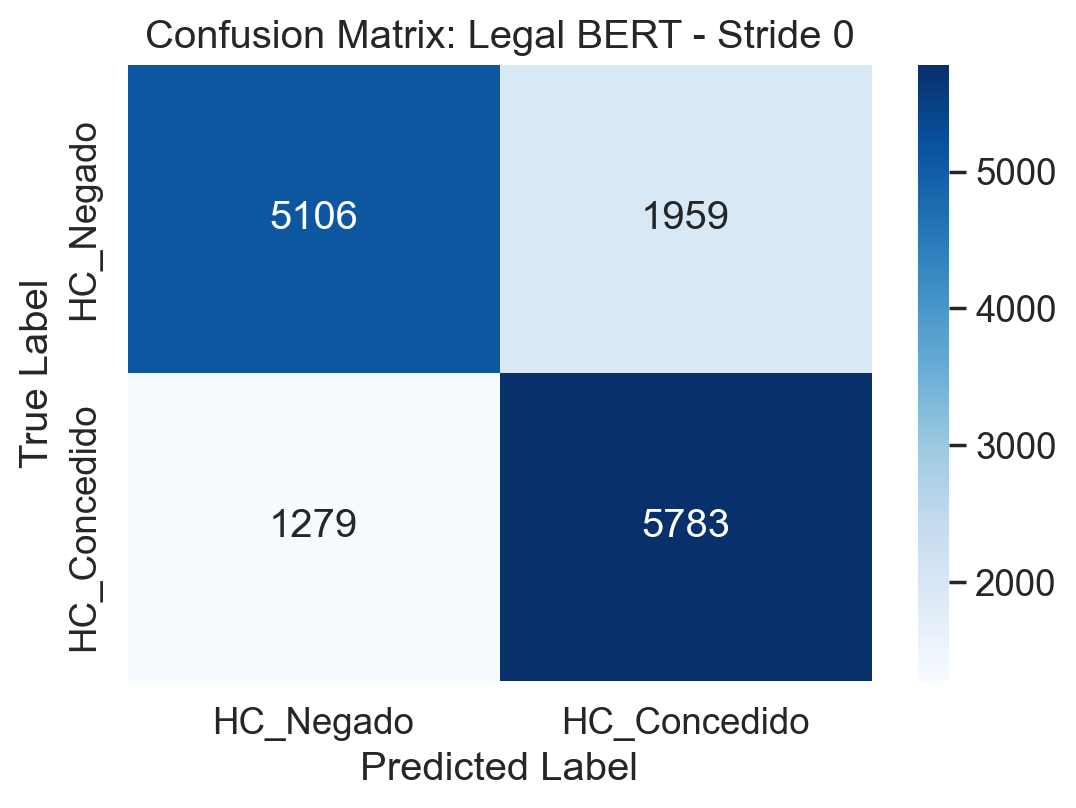


Analisando cenário: BERTimbau Base (Mean Pooling - Stride 384)
Chave: BERTimbau Base||Mean Pooling - Stride 384||LONG||v4||A-100
✨ [CACHE HIT] Dados carregados diretamente da memória física do cache para evitar processamento pesado em GPU!
📊 Resultados - F1-Score: 0.7520 | AUC: 0.8328 | Accuracy: 0.7528


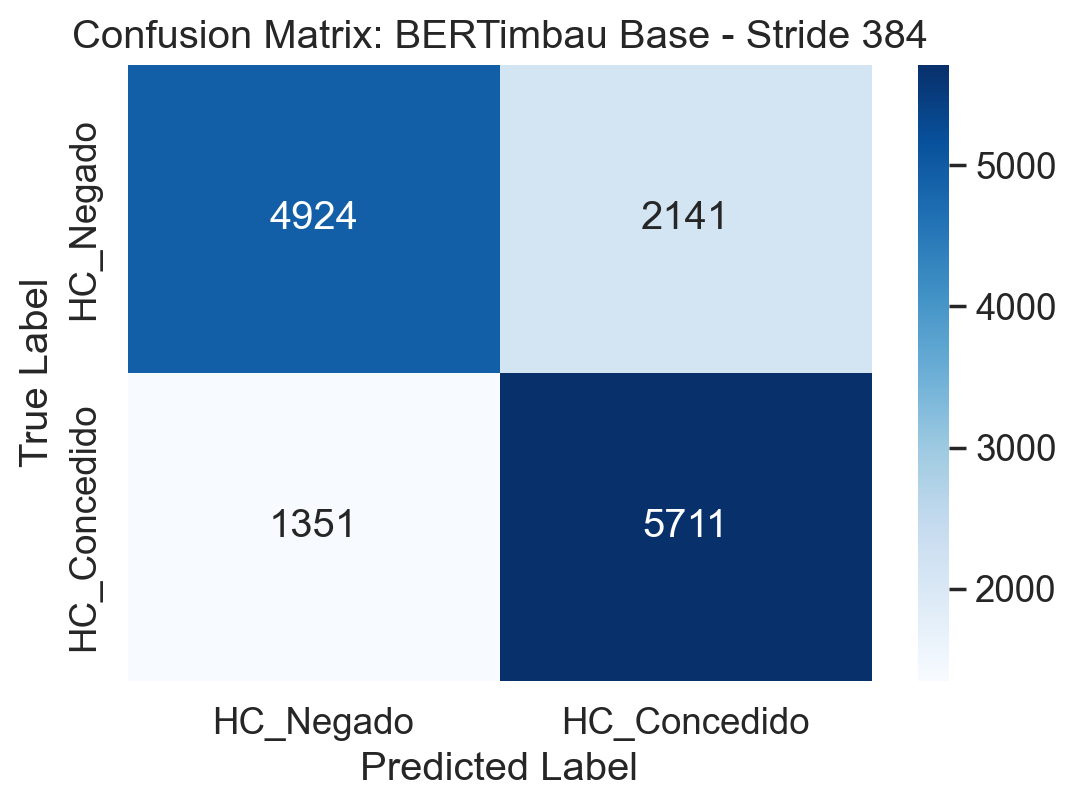


Analisando cenário: Legal BERTimbau (Mean Pooling - Stride 384)
Chave: Legal-BERTimbau-base||Mean Pooling - Stride 384||LONG||v4||A-100
✨ [CACHE HIT] Dados carregados diretamente da memória física do cache para evitar processamento pesado em GPU!
📊 Resultados - F1-Score: 0.7418 | AUC: 0.8246 | Accuracy: 0.7422


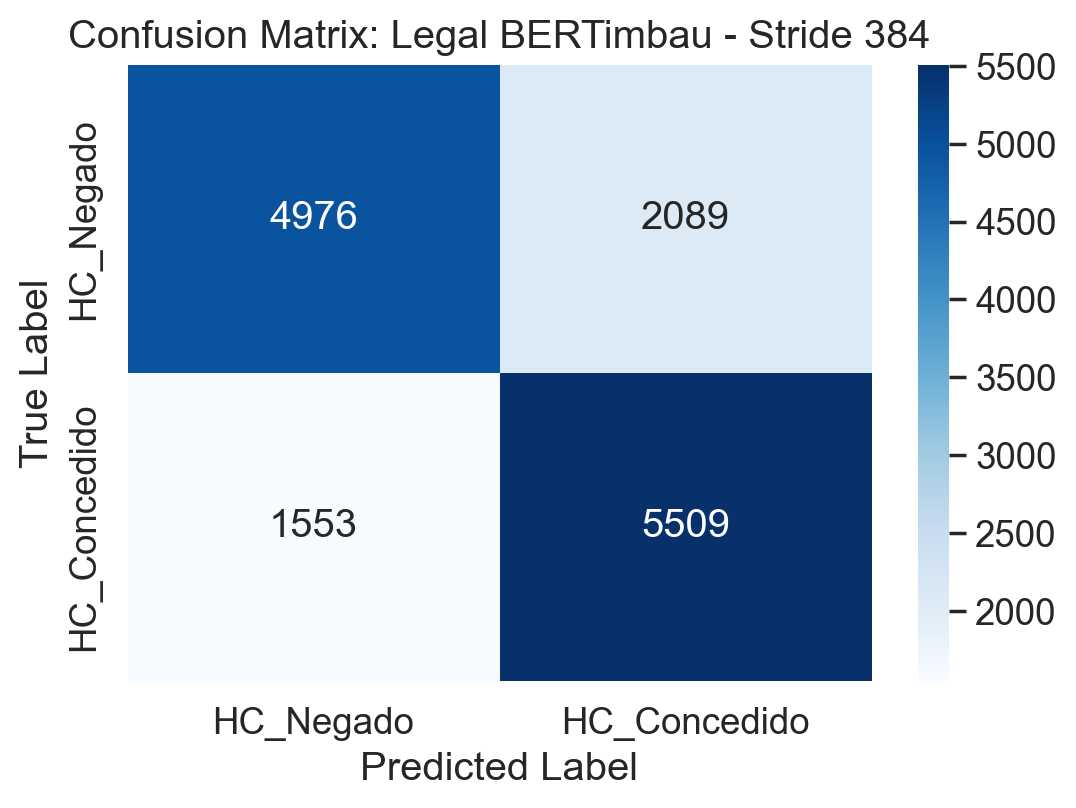


Analisando cenário: BERT Multilingual (Mean Pooling - Stride 0)
Chave: BERT Multilingual Base||Mean Pooling - Stride 0||LONG||v4||A-100
✨ [CACHE HIT] Dados carregados diretamente da memória física do cache para evitar processamento pesado em GPU!
📊 Resultados - F1-Score: 0.6924 | AUC: 0.7789 | Accuracy: 0.6961


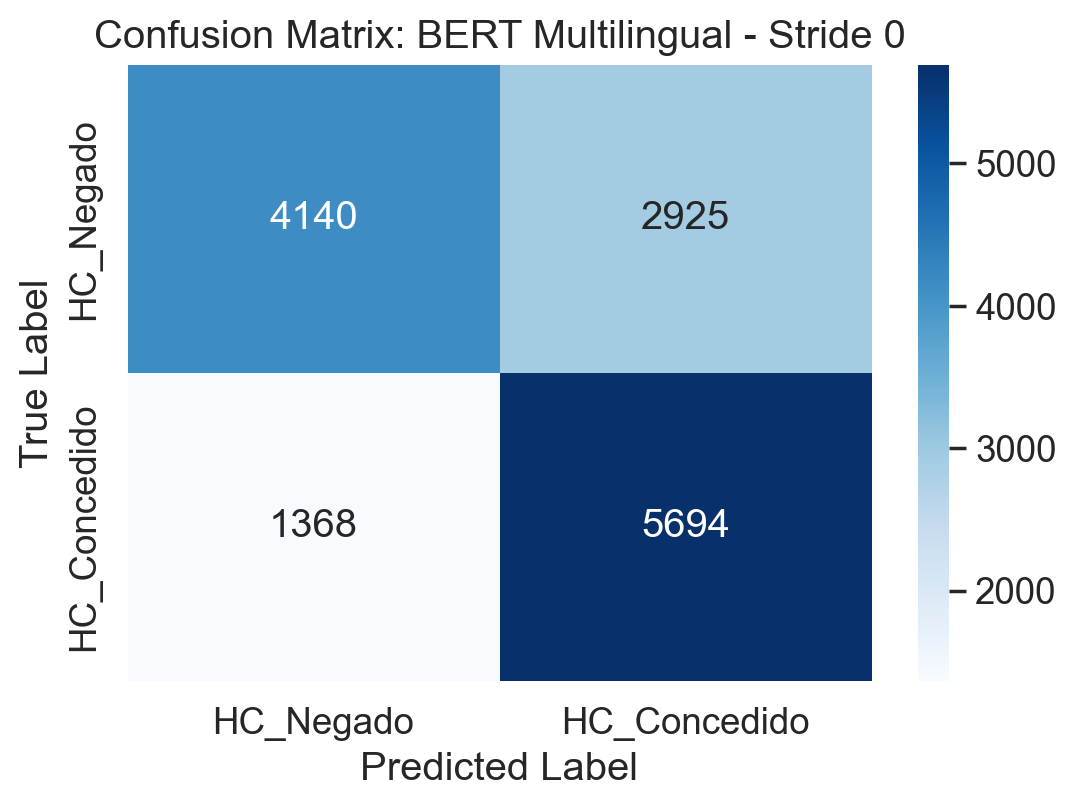


Analisando cenário: Legal BERT (Mean Pooling - Stride 448)
Chave: legalbertpt_fp||Mean Pooling - Stride 448||LONG||v4||A-100
⚡ [CACHE MISS] Inferência não encontrada para este cenário. Iniciando processamento GPU...
[Erro] Approach 'Mean Pooling - Stride 448' não configurado. Ignorando...

Analisando cenário: Legal BERT (Max Pooling - Stride 448)
Chave: legalbertpt_fp||Max Pooling - Stride 448||LONG||v4||A-100
⚡ [CACHE MISS] Inferência não encontrada para este cenário. Iniciando processamento GPU...
[Erro] Approach 'Max Pooling - Stride 448' não configurado. Ignorando...


In [ ]:
#INFERENCE MODE COM SUPORTE A CACHE DE METADADOS
import gc
import time
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print(f"Using pre-loaded df_test for inference with DATASET_TYPE: {DATASET_TYPE}")

#hardware_used = get_hardware_name()
hardware_used = 'A-100'
cache = load_inference_cache()
all_inference_roc_data = []
inference_results = []

for config in LIST_MODEL_INFERENCE_TRAINED:
    model_id = config['id_model']
    endpoint, model_name_tag = get_model_config(model_id)
    model_label = config.get('label', model_name_tag)
    target_approach_label = config.get('approach')

    if not target_approach_label:
        continue

    # Recuperar sufixo de versão correto
    local_dataset_version = config.get('dataset_version')
    actual_dataset_version = local_dataset_version if local_dataset_version not in [None, -1] else DATASET_VERSION

    # Gerar chave única para este cenário baseado nos requisitos do usuário
    cache_key = generate_cache_key(
        model_name=model_name_tag,
        approach=target_approach_label,
        database_type=DATASET_TYPE,
        database_version=actual_dataset_version,
        hardware=hardware_used
    )

    print(f"\n{'='*80}\nAnalisando cenário: {model_label} ({target_approach_label})\nChave: {cache_key}\n{'='*80}")

    # Verifica se os resultados já estão no cache
    if cache_key in cache:
        print(f"✨ [CACHE HIT] Dados carregados diretamente da memória física do cache para evitar processamento pesado em GPU!")
        entry = cache[cache_key]
        probs_pos = np.array(entry['probs_positive'])
        y_test_np = np.array(entry['y_true'])
        y_pred_np = np.array(entry['y_pred'])

        acc = entry['metrics']['accuracy']
        f1 = entry['metrics']['f1']
        roc_auc = entry['metrics']['auc']
        fpr = np.array(entry['roc']['fpr'])
        tpr = np.array(entry['roc']['tpr'])
    else:
        print(f"⚡ [CACHE MISS] Inferência não encontrada para este cenário. Iniciando processamento GPU...")
        # Configuração inicial do tokenizador e modelo
        tokenizer = AutoTokenizer.from_pretrained(endpoint, use_fast=True)
        model_entry = next(m for m in LIST_MODEL_CHECKPOINT if m['id'] == model_id)
        num_layers = model_entry['num-layers']

        approach_cfg = next((app for app in APPROACHES if app['label'] == target_approach_label), None)
        if not approach_cfg:
            print(f"[Erro] Approach '{target_approach_label}' não configurado. Ignorando...")
            continue

        actual_version_suffix = "" if local_dataset_version == -1 else (f"_v{actual_dataset_version}" if PLACE_DATASET_VERION_IN_MODEL else "")
        local_suffix_model_name = config.get('suffix_model_name')
        actual_suffix_model_name = local_suffix_model_name if local_suffix_model_name is not None else SUFIX_MODEL_NAME

        model_file_name = f'best_model_{model_name_tag}_{get_safe_label(target_approach_label)}_{DATASET_TYPE}{actual_version_suffix}_{actual_suffix_model_name}.bin'
        model_path = os.path.join(BASE_MODEL_SAVED, model_file_name)

        if not os.path.exists(model_path):
            print(f"[Erro] Modelo ausente no Drive: {model_path}. Ignorando...")
            continue

        # Inicializar rede e carregar pesos
        model = HCAcordaoClassifier(len(class_names), num_layers, endpoint, pooling_strategy=approach_cfg.get('pooling', 'max')).to(device)
        model.load_state_dict(torch.load(model_path, map_location=device))

        test_loader = create_data_loader(
            df_test, tokenizer, CHUNK_SIZE, approach_cfg['stride'], approach_cfg['batch_size'],
            approach_cfg.get('max_chunks', 30), approach_cfg.get('min_chunk_tokens', 8), shuffle=False
        )

        y_pred, y_pred_probs, y_test = get_predictions(model, test_loader, device)
        probs = torch.nn.functional.softmax(y_pred_probs, dim=1).detach().cpu().numpy()

        y_test_np = y_test.cpu().numpy()
        y_pred_np = y_pred.cpu().numpy()
        probs_pos = probs[:, 1]

        acc = accuracy_score(y_test_np, y_pred_np)
        prec, rec, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='macro', zero_division=0)
        fpr, tpr, _ = roc_curve(y_test_np, probs_pos)
        roc_auc = auc(fpr, tpr)

        # Grava os resultados calculados nesta rodada no cache local
        cache[cache_key] = {
            'probs_positive': probs_pos.tolist(),
            'y_true': y_test_np.tolist(),
            'y_pred': y_pred_np.tolist(),
            'metrics': {
                'accuracy': float(acc),
                'f1': float(f1),
                'auc': float(roc_auc)
            },
            'roc': {
                'fpr': fpr.tolist(),
                'tpr': tpr.tolist()
            }
        }
        save_inference_cache(cache)

        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Métricas consolidadas finais para uso nos próximos blocos (ex: Curvas ROC)
    print(f"📊 Resultados - F1-Score: {f1:.4f} | AUC: {roc_auc:.4f} | Accuracy: {acc:.4f}")
    inference_results.append({
        'Model': model_label,
        'Approach': target_approach_label,
        'F1-Score': f1,
        'AUC': roc_auc
    })

    graphic_label = config.get('graphic_label', target_approach_label)
    all_inference_roc_data.append((model_name_tag, graphic_label, fpr, tpr, roc_auc))

    # Gerar Matriz de Confusão do cenário atual
    cm = confusion_matrix(y_test_np, y_pred_np)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix: {model_label} - {graphic_label}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

In [ ]:
gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None


## `📊` ROC Curve

In [ ]:
SAVE_ROC_IMAGE = False
NAME_GRAPHIC = 'best_approachs'

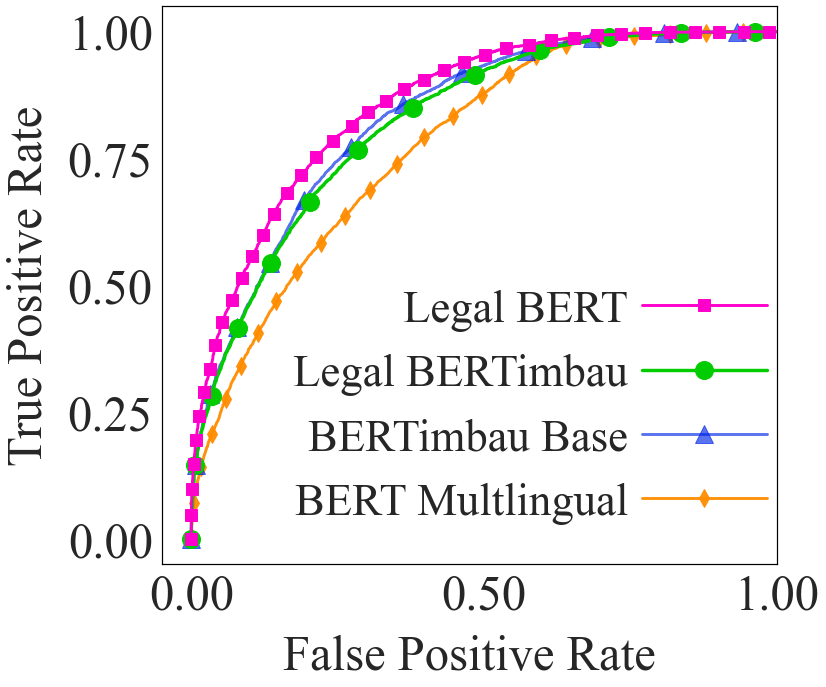

In [ ]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman']
})

FONT_SIZE = 50

if all_inference_roc_data:
    fig, ax = plt.subplots(figsize=(12, 10), dpi=500 if SAVE_ROC_IMAGE else 35)

    # Ordena os dados de ROC de forma decrescente pelo valor do AUC
    #sorted_roc_data = sorted(all_inference_roc_data, key=lambda x: x[4], reverse=True)

    # Dicionário para armazenar as linhas para controle exato da legenda
    lines_for_legend = {}

    # Criar o gráfico principal
    for model_tag, label, fpr, tpr, roc_auc in all_inference_roc_data:
        # Determina o nome amigável e estilização para o artigo científico
        if "legalbertpt" in model_tag:
            model_display_name = "Legal BERT"
            color = "#FF00CC"  # Magenta / Rosa vibrante (curva superior)
            marker = "s"  # Quadrados pequenos
            markersize = 12.5
            markevery = 0.03  # Frequência maior de marcadores ao longo da curva
            linestyle = "-"  # Linha contínua fina
            linewidth = 3.0
            alpha = 1.0
            zorder = 4
            priority = 1

        elif "Legal-BERTimbau" in model_tag:
            model_display_name = "Legal BERTimbau"
            color = "#00CC00"  # Verde vibrante
            marker = "o"  # Marcador em formato de x / cruz
            markersize = 18.5
            markevery = 0.09
            linestyle = "-"
            linewidth = 3.5
            alpha = 1.0
            zorder = 3
            priority = 2

        elif "BERTimbau Base" in model_tag:
            model_display_name = "BERTimbau Base"
            color = "#0026E6"  # Azul royal intenso
            marker = "^"  # Triângulos pequenos
            markersize = 18.5
            markevery = 0.09
            linestyle = "-"
            linewidth = 3.0
            alpha = 0.65
            zorder = 2
            priority = 3

        elif "BERT Multilingual" in model_tag:
            model_display_name = "BERT Multlingual"
            color = "#FF8C00"  # Laranja escuro / âmbar para contraste e legibilidade
            marker = "d"  # Losango pequeno
            markersize = 12.5
            markevery = 0.045
            linestyle = "-"
            linewidth = 3.0
            alpha = 0.95
            zorder = 1
            priority = 4

        # Plota a curva do modelo utilizando APENAS o nome na legenda (sem o AUC)
        line, = ax.plot(
            fpr,
            tpr,
            label=f"{model_display_name}",
            color=color,
            linestyle=linestyle,
            linewidth=linewidth,
            marker=marker,
            markersize=markersize,
            markevery=markevery,
            alpha=alpha,
            zorder=zorder,
        )

        # Salva a linha junto com a prioridade para ordenação da legenda
        lines_for_legend[priority] = line

    ax.set_xlim([-0.05, 1.0])
    ax.set_ylim([-0.05, 1.05])

    # Escalas formatadas conforme padrão acadêmico e ticks aumentados
    ax.set_xticks([0.0, 0.5, 1.0])
    ax.set_xticklabels(["0.00", "0.50", "1.00"], fontsize=FONT_SIZE)
    ax.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0.00", "0.25", "0.50", "0.75", "1.00"], fontsize=FONT_SIZE)

    ax.set_xlabel('False Positive Rate', fontsize=FONT_SIZE, labelpad=15)
    ax.set_ylabel('True Positive Rate', fontsize=FONT_SIZE, labelpad=15)

    # Ordena as handles da legenda baseada na prioridade definida
    sorted_handles = [lines_for_legend[p] for p in sorted(lines_for_legend.keys())]
    sorted_labels = [h.get_label() for h in sorted_handles]

    # Legenda customizada exibindo apenas os nomes dos modelos na ordem desejada
    # Ajuste de bbox_to_anchor para mover mais à direita
    ax.legend(sorted_handles, sorted_labels, loc="lower right", fontsize=FONT_SIZE-4, bbox_to_anchor=(1.05, 0),
              frameon=False, markerfirst=False, handlelength=2.8, handletextpad=0.3)
    ax.grid(False)

    # Ajustes finais da borda do gráfico principal
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_visible(True)

    plt.tight_layout()

    if SAVE_ROC_IMAGE:
        roc_image_path = os.path.join(BASE_MODEL_SAVED, f'roc_curve_inference_{NAME_GRAPHIC}_{DATASET_TYPE}.pdf')
        plt.savefig(roc_image_path, format='pdf', bbox_inches='tight')
        print(f"Imagem da Curva ROC salva em: {roc_image_path}")

    plt.show()
else:
    print("No valid models found for inference to plot ROC.")

In [ ]:
2/0

ZeroDivisionError: division by zero

## Inferência para fins de TRADE-OFF

In [ ]:
file_path = f"{BASE_PATH_DATASET}preprocessed_HC_geral_2021_2025_inference.csv"

df_inference = pd.read_csv(file_path, sep=";", nrows=None)

In [ ]:
import gc
import torch
import os
import time
import csv
from torch.amp import autocast

log_event_path = os.path.join(BASE_MODEL_SAVED, 'log_trade_off_events.csv')

# Garantir que a coluna 'classe' exigida pelo Dataset (HCAcordao) exista no df_inference,
# mesmo não usando para avaliação (pois o Dataset requer ela para instanciar targets).
if 'classe' not in df_inference.columns:
    if 'DECISAO_FAVORAVEL' in df_inference.columns:
        df_inference['classe'] = df_inference['DECISAO_FAVORAVEL'].apply(cast_decisao_to_int)
    else:
        df_inference['classe'] = 0

print("Iniciando inferência por evento para Trade-off...")

# Extraindo as colunas baseadas na primeira configuração, excluindo 'graphic_label' e 'suffix_model_name'
if len(LIST_MODEL_INFERENCE_TRAINED) > 0:
    base_keys = [k for k in LIST_MODEL_INFERENCE_TRAINED[0].keys() if k not in ['graphic_label', 'suffix_model_name']]
else:
    base_keys = []

fields = base_keys + ['NUMEROREGISTRO', 'NUM_TOKENS_RELATORIO', 'TIPODOCUMENTO', 'inference_time_ms']

file_exists = os.path.isfile(log_event_path)
with open(log_event_path, 'a', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fields, delimiter=';')
    if not file_exists:
        writer.writeheader()

for config in LIST_MODEL_INFERENCE_TRAINED:
    model_id = config['id_model']
    endpoint, model_name_tag = get_model_config(model_id)
    target_approach_label = config.get('approach')

    approach_cfg = next((app for app in APPROACHES if app['label'] == target_approach_label), None)
    if not approach_cfg:
        continue

    approach_label = approach_cfg['label']
    safe_label = get_safe_label(approach_label)

    local_dataset_version = config.get('dataset_version')
    actual_dataset_version = local_dataset_version if local_dataset_version not in [None, -1] else DATASET_VERSION
    actual_version_suffix = f"_v{actual_dataset_version}" if PLACE_DATASET_VERION_IN_MODEL and local_dataset_version != -1 else ""

    local_suffix_model_name = config.get('suffix_model_name')
    actual_suffix_model_name = local_suffix_model_name if local_suffix_model_name is not None else SUFIX_MODEL_NAME

    model_file_name = f'best_model_{model_name_tag}_{safe_label}_{DATASET_TYPE}{actual_version_suffix}_{actual_suffix_model_name}.bin'
    model_path = os.path.join(BASE_MODEL_SAVED, model_file_name)

    if not os.path.exists(model_path):
        print(f"[Skip] Modelo não encontrado: {model_path}")
        continue

    print(f"\n-> Carregando modelo: {model_file_name}")
    tokenizer = AutoTokenizer.from_pretrained(endpoint, use_fast=True)
    model_entry = next(m for m in LIST_MODEL_CHECKPOINT if m['id'] == model_id)

    model = HCAcordaoClassifier(len(class_names), model_entry['num-layers'], endpoint, pooling_strategy=approach_cfg.get('pooling', 'max')).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    # Dataloader com batch_size=1 para inferência precisa por evento
    event_loader = create_data_loader(
        df_inference, tokenizer, CHUNK_SIZE, approach_cfg['stride'],
        1, approach_cfg.get('max_chunks', 30), approach_cfg.get('min_chunk_tokens', 8),
        shuffle=False, approach_label=approach_label, seed=RANDOM_SEED
    )

    total_records = len(df_inference)
    print(f"   Executando predições evento a evento para {total_records} registros...")

    results_to_save = []
    base_record = {k: config[k] for k in base_keys if k in config}
    progress_step = max(1, total_records // 10)

    for i, (row, d) in enumerate(zip(df_inference.itertuples(), event_loader), 1):
        input_ids = d["input_ids"].to(device)
        attention_mask = d["attention_mask"].to(device)
        chunk_counts = d["chunk_counts"].to(device)

        if i == 1:
            # Warm-up: inferência extra no primeiro registro para evitar overhead de inicialização (lazy init) da GPU
            with torch.no_grad(), autocast('cuda'):
                _ = model(input_ids=input_ids, attention_mask=attention_mask, chunk_counts=chunk_counts)
            if torch.cuda.is_available():
                torch.cuda.synchronize()

        # Sincronização CUDA para garantir a precisão de tempo das operações assíncronas de GPU
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        start_t = time.perf_counter()

        with torch.no_grad(), autocast('cuda'):
            _ = model(input_ids=input_ids, attention_mask=attention_mask, chunk_counts=chunk_counts)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        end_t = time.perf_counter()

        inf_time_ms = (end_t - start_t) * 1000

        record = dict(base_record)

        # Garante que o log no CSV registre a versão real utilizada do dataset, mesmo quando for inferência sem sufixo (-1)
        record['dataset_version'] = actual_dataset_version

        # Tratamento da métrica AUC do Treino baseado no tamanho do texto do evento
        auc_train_val = record.get('auc_train', 0)
        if isinstance(auc_train_val, dict):
            texto_longo_val = getattr(row, 'TEXTO_LONGO', 'N')
            if texto_longo_val == 'S':
                record['auc_train'] = auc_train_val.get('long', 0)
            else:
                record['auc_train'] = auc_train_val.get('small', 0)

        record['NUMEROREGISTRO'] = getattr(row, 'NUMEROREGISTRO', '')
        record['NUM_TOKENS_RELATORIO'] = getattr(row, 'NUM_TOKENS_RELATORIO', '')
        record['TIPODOCUMENTO'] = getattr(row, 'TIPODOCUMENTO', '')
        record['inference_time_ms'] = round(inf_time_ms, 4)

        results_to_save.append(record)

        if i % progress_step == 0 or i == total_records:
            print(f"      Progresso: {i}/{total_records} ({(i/total_records)*100:.1f}%)")

    # Salva todos os eventos testados para o modelo no log csv
    with open(log_event_path, 'a', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fields, delimiter=';')
        writer.writerows(results_to_save)

    print(f"   Salvo(s) {len(results_to_save)} logs de evento no arquivo: {log_event_path}")

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nInferência de Trade-off por evento concluída com sucesso!")